# 🎓 TP 2 — Supervised Learning: Linear, Polynomial & Regularized Regression
**Master 1 Artificial Intelligence — Machine Learning Practical Course**

---

## 📌 Context and Objectives

In this practical work (**TP 2**), we study **Supervised Regression** on the clinical **Diabetes dataset** (442 patients, 10 physiological predictors, continuous progression score).

We partition the data into **80% training ($n=353$)** and **20% testing ($n=89$)** using a fixed random seed (`random_state=42`) without generating any artificial data.

### Organized Model Progression:
1. **Model 1: Simple Linear Regression (SLR)** — Baseline using Body Mass Index (`bmi`).
2. **Model 2: Multiple Linear Regression (MLR)** — Ordinary Least Squares (OLS) using all 10 features.
3. **Model 3: Polynomial Regression (Degree 2, OLS)** — Non-linear expansion with `StandardScaler` (demonstrating overfitting).
4. **Model 4: Ridge Regression ($L_2$)** — Linear regression with weight shrinkage and 5-fold cross-validation.
5. **Model 5: Lasso Regression ($L_1$)** — Linear regression with feature selection / sparsity and 5-fold cross-validation.
6. **Model 6: Polynomial Ridge Regression (Poly + $L_2$)** — Taming polynomial overfitting via $L_2$ penalty in a `Pipeline`.
7. **Model 7: Polynomial Lasso Regression (Poly + $L_1$)** — Non-linear feature selection via $L_1$ penalty in a `Pipeline`.
8. **Master Evaluation & Comparison** — Comprehensive evaluation table and diagnostic plots on the untouched 20% test set.


# ==========================================================================
# 1. Environment Setup & Configuration
# ==========================================================================

We import the essential scientific libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`, and Scikit-Learn tools.
We set a fixed global random seed `RANDOM_STATE = 42` for exact reproducibility.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-Learn tools
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Statsmodels for VIF collinearity check
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Styling settings
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Reproducibility seed
RANDOM_STATE = 42

# Path configuration
cwd = os.getcwd()
if os.path.basename(cwd) == "notebooks":
    TP2_ROOT = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.basename(cwd) == "tp2":
    TP2_ROOT = os.path.abspath(cwd)
else:
    TP2_ROOT = os.path.abspath(os.path.join(cwd, "tp2"))

DATA_DIR = os.path.join(TP2_ROOT, "data")
PLOTS_DIR = os.path.join(TP2_ROOT, "plots")
RESULTS_DIR = os.path.join(TP2_ROOT, "results")

for subdir in ["distributions", "correlations", "simple_regression", "multiple_regression", "regularization", "polynomial_regression", "evaluation"]:
    os.makedirs(os.path.join(PLOTS_DIR, subdir), exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print(f"Setup complete! Root directory: {TP2_ROOT}")


Setup complete! Root directory: /home/ays/AI_Apps/ml_univ/tp2


# ==========================================================================
# 2. Dataset Loading, Inspection and Data Understanding
# ==========================================================================

### Dataset Clinical Background
The dataset utilized in this practical work is the benchmark **Diabetes dataset** introduced by Bradley Efron, Trevor Hastie, Iain Johnstone, and Robert Tibshirani (2004) in their foundational paper *"Least Angle Regression"*, Annals of Statistics.

The dataset records **442 diabetes patients** and comprises **10 baseline physiological predictor variables** and **1 quantitative target variable**:

| Feature Name | Description | Biological / Clinical Significance |
| :--- | :--- | :--- |
| `age` | Patient age in years | Natural aging factor in metabolic degradation |
| `sex` | Patient biological sex | Hormonal differences impacting insulin resistance |
| `bmi` | Body Mass Index ($kg/m^2$) | Key indicator of obesity and metabolic syndrome |
| `bp` | Average blood pressure ($mmHg$) | Vascular health and cardiovascular risk factor |
| `s1` (`tc`) | Total serum cholesterol | Blood lipid profile component |
| `s2` (`ldl`) | Low-density lipoproteins | "Bad" cholesterol carrying lipids into arteries |
| `s3` (`hdl`) | High-density lipoproteins | "Good" cholesterol removing lipids from circulation |
| `s4` (`tch`) | Total cholesterol / HDL ratio | Atherogenic index; ratio of total lipids to protective HDL |
| `s5` (`ltg`) | Log of serum triglycerides level | Blood fat concentration linked to insulin sensitivity |
| `s6` (`glu`) | Blood glucose sugar level | Direct indicator of glycemic control |

**Target Variable (`target`):**
A quantitative measure of **disease progression** recorded one full year after baseline measurement (continuous integer score ranging from 25 to 346). 
> **Important Distinction:** This is a **regression** problem predicting *disease severity progression over time*, **not** a classification problem diagnosing whether a patient has diabetes.

### Scikit-Learn Pre-Scaling Note:
In `load_diabetes(as_frame=True)`, each of the 10 feature columns has already been **mean-centered to 0** and scaled such that the sum of squares across each column equals 1:
$$\sum_{i=1}^n x_{ij}^2 = 1 \implies \text{std}(x_j) = \frac{1}{\sqrt{n}} \approx 0.0476$$
Consequently, the features are already standardized to comparable numerical ranges, though they are not in original medical units.

In [2]:
# Load Scikit-Learn Diabetes dataset as a Pandas DataFrame
diabetes_bunch = load_diabetes(as_frame=True)
df = diabetes_bunch.frame.copy()

# Save reproducible local copy inside tp2/data/
local_csv_path = os.path.join(DATA_DIR, "diabetes.csv")
df.to_csv(local_csv_path, index=False)
print(f"Dataset successfully loaded and verified at: {local_csv_path}")

# Display first 5 and last 5 rows of the dataset
print("\n--- First 5 Observations ---")
display(df.head())

print("\n--- Last 5 Observations ---")
display(df.tail())

Dataset successfully loaded and verified at: /home/ays/AI_Apps/ml_univ/tp2/data/diabetes.csv

--- First 5 Observations ---


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



--- Last 5 Observations ---


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0
441,-0.045472,-0.044642,-0.073030,-0.081413,0.083740,0.027809,0.173816,-0.039493,-0.004222,0.003064,57.0


In [3]:
# Display dimensions, column names, and data types
print("=== DATASET DIMENSIONS ===")
print(f"Total Observations (rows):    {df.shape[0]}")
print(f"Total Attributes (columns):   {df.shape[1]} (10 features + 1 target)")

print("\n=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

print("\n=== DATASET GENERAL INFO ===")
df.info()

=== DATASET DIMENSIONS ===
Total Observations (rows):    442
Total Attributes (columns):   11 (10 features + 1 target)

=== COLUMN NAMES AND DATA TYPES ===
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

=== DATASET GENERAL INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory 

In [4]:
# Compute and display descriptive statistics for all features and the target
print("=== DESCRIPTIVE STATISTICS ===")
display(df.describe().round(4))

# Inspect target variable specific distribution properties
target_series = df["target"]
print("=== TARGET VARIABLE ('target') SUMMARY ===")
print(f"Count:      {target_series.count()}")
print(f"Mean:       {target_series.mean():.2f}")
print(f"Std Dev:    {target_series.std():.2f}")
print(f"Median:     {target_series.median():.2f}")
print(f"Min:        {target_series.min():.2f}")
print(f"Max:        {target_series.max():.2f}")
print(f"IQR:        {(target_series.quantile(0.75) - target_series.quantile(0.25)):.2f}")
print(f"Skewness:   {target_series.skew():.3f} (moderately right-skewed)")

=== DESCRIPTIVE STATISTICS ===


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


=== TARGET VARIABLE ('target') SUMMARY ===
Count:      442
Mean:       152.13
Std Dev:    77.09
Median:     140.50
Min:        25.00
Max:        346.00
IQR:        124.50
Skewness:   0.441 (moderately right-skewed)


# ==========================================================================
# 3. Data Preprocessing & Leakage-Free Train/Test Split
# ==========================================================================

Before training regression models, we conduct a disciplined preprocessing audit:
1. **Missing Values Audit:** Detect if any null, NaN, or corrupted values exist.
2. **Duplicate Detection:** Identify identical patient records.
3. **Data Type Verification:** Confirm numerical consistency across all columns.
4. **Outlier Investigation:** Examine distribution tails using Tukey's Interquartile Range (IQR) rule:
   $$\text{IQR} = Q_3 - Q_1, \quad [\text{Lower Bound} = Q_1 - 1.5 \cdot \text{IQR}, \quad \text{Upper Bound} = Q_3 + 1.5 \cdot \text{IQR}]$$
   *Pedagogical Insight:* In clinical datasets, extreme readings (e.g., severe obesity or acute hyperlipidemia) often represent **genuine biological variability** rather than sensor malfunctions. Removing them blindly would discard high-risk patient signals and impair real-world clinical generalization.
5. **Leakage-Free Train/Test Split:** We partition the dataset into 80% Training ($n=353$) and 20% Testing ($n=89$) using a fixed seed (`random_state=42`). 
   > **Golden Rule of Machine Learning:** All exploratory transformations, scaler parameters (mean $\mu$ and standard deviation $\sigma$), and hyperparameter tuning must be computed **strictly on the training partition**. The test partition remains completely untouched until final evaluation to prevent **data leakage**.

In [5]:
# 1. Missing Values Audit
missing_per_col = df.isnull().sum()
missing_per_row = df.isnull().sum(axis=1).value_counts()

print("=== MISSING VALUE AUDIT ===")
print("Missing values per column:")
print(missing_per_col)
print(f"\nTotal missing values across entire dataset: {missing_per_col.sum()}")

# 2. Duplicate Detection
num_duplicates = df.duplicated().sum()
print(f"\n=== DUPLICATE RECORD AUDIT ===")
print(f"Number of duplicate rows: {num_duplicates}")
if num_duplicates == 0:
    print("Verification confirmed: No duplicate patient records exist.")

=== MISSING VALUE AUDIT ===
Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Total missing values across entire dataset: 0

=== DUPLICATE RECORD AUDIT ===
Number of duplicate rows: 0
Verification confirmed: No duplicate patient records exist.


In [6]:
# 3. Outlier Investigation using Tukey's Interquartile Range (IQR) Rule
def analyze_iqr_outliers(data):
    records = []
    for col in data.columns:
        s = data[col]
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = s[(s < lower_bound) | (s > upper_bound)]
        records.append({
            "Feature": col,
            "Q1": round(q1, 4),
            "Q3": round(q3, 4),
            "IQR": round(iqr, 4),
            "Lower Bound": round(lower_bound, 4),
            "Upper Bound": round(upper_bound, 4),
            "Outlier Count": len(outliers),
            "Outlier %": round((len(outliers) / len(s)) * 100, 2)
        })
    return pd.DataFrame(records)

iqr_summary = analyze_iqr_outliers(df)
print("=== IQR OUTLIER SUMMARY TABLE ===")
display(iqr_summary)

=== IQR OUTLIER SUMMARY TABLE ===


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age,-0.0373,0.0381,0.0754,-0.1504,0.1511,0,0.00
1,sex,-0.0446,0.0507,0.0953,-0.1876,0.1937,0,0.00
2,bmi,-0.0342,0.0312,0.0655,-0.1324,0.1295,3,0.68
3,bp,-0.0367,0.0356,0.0723,-0.1451,0.1441,0,0.00
4,s1,-0.0342,0.0284,0.0626,-0.1282,0.1223,8,1.81
5,s2,-0.0304,0.0298,0.0602,-0.1207,0.1201,7,1.58
6,s3,-0.0351,0.0293,0.0644,-0.1318,0.1260,7,1.58
7,s4,-0.0395,0.0343,0.0738,-0.1502,0.1450,2,0.45
8,s5,-0.0332,0.0324,0.0657,-0.1318,0.1309,4,0.90
9,s6,-0.0332,0.0279,0.0611,-0.1248,0.1196,9,2.04


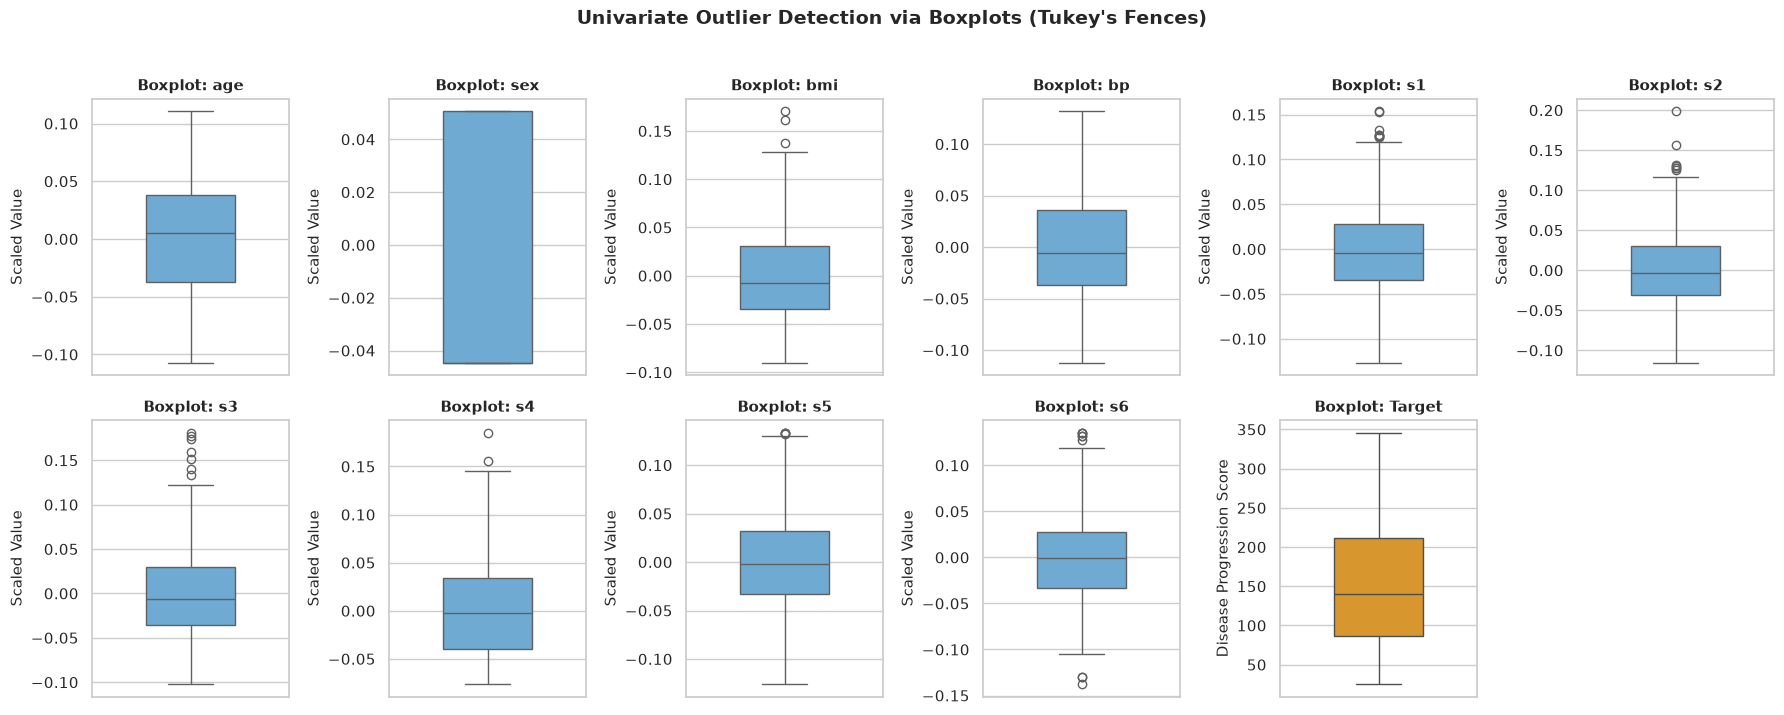

Boxplot visualization saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/features_boxplots.png


In [7]:
# Visualize Boxplots for All 10 Features and the Target
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
axes = axes.flatten()

feature_cols = [c for c in df.columns if c != "target"]

for idx, col in enumerate(feature_cols):
    sns.boxplot(y=df[col], ax=axes[idx], color="#5dade2", width=0.45)
    axes[idx].set_title(f"Boxplot: {col}", fontweight="bold", fontsize=11)
    axes[idx].set_ylabel("Scaled Value")

# Plot target in slot 10
sns.boxplot(y=df["target"], ax=axes[10], color="#f39c12", width=0.45)
axes[10].set_title("Boxplot: Target", fontweight="bold", fontsize=11)
axes[10].set_ylabel("Disease Progression Score")

# Remove unused 12th subplot
fig.delaxes(axes[11])

plt.suptitle("Univariate Outlier Detection via Boxplots (Tukey's Fences)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

boxplot_path = os.path.join(PLOTS_DIR, "distributions", "features_boxplots.png")
plt.savefig(boxplot_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Boxplot visualization saved to: {boxplot_path}")

In [8]:
# 4. Partition into Features (X) and Target (y)
X = df.drop(columns=["target"]).copy()
y = df["target"].copy()

# 5. Train/Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("=== TRAIN / TEST SPLIT COMPLETED ===")
print(f"X_train shape: {X_train.shape} (353 samples, 10 features)")
print(f"y_train shape: {y_train.shape} (353 target observations)")
print(f"X_test shape:  {X_test.shape}  (89 samples, 10 features)")
print(f"y_test shape:  {y_test.shape}  (89 target observations)")
print(f"Split ratio:   {len(y_train)/len(df):.1%} Training / {len(y_test)/len(df):.1%} Testing")

=== TRAIN / TEST SPLIT COMPLETED ===
X_train shape: (353, 10) (353 samples, 10 features)
y_train shape: (353,) (353 target observations)
X_test shape:  (89, 10)  (89 samples, 10 features)
y_test shape:  (89,)  (89 target observations)
Split ratio:   79.9% Training / 20.1% Testing


# ==========================================================================
# 4. Exploratory Data Analysis (EDA)
# ==========================================================================

In this exploratory phase, we investigate:
1. **Feature Distributions:** Shape, symmetry, and spread of each physiological predictor.
2. **Target Distribution:** Central tendency and skewness of diabetes progression.
3. **Correlation Analysis:** The Pearson correlation coefficient matrix $r_{xy} \in [-1, 1]$:
   $$r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}$$
4. **Feature vs. Target Associations:** Linear trends and scatter plots to identify predictors exhibiting the strongest linear predictive potential.
> **Caution:** Correlation measures linear association; it does **not** imply medical causation.

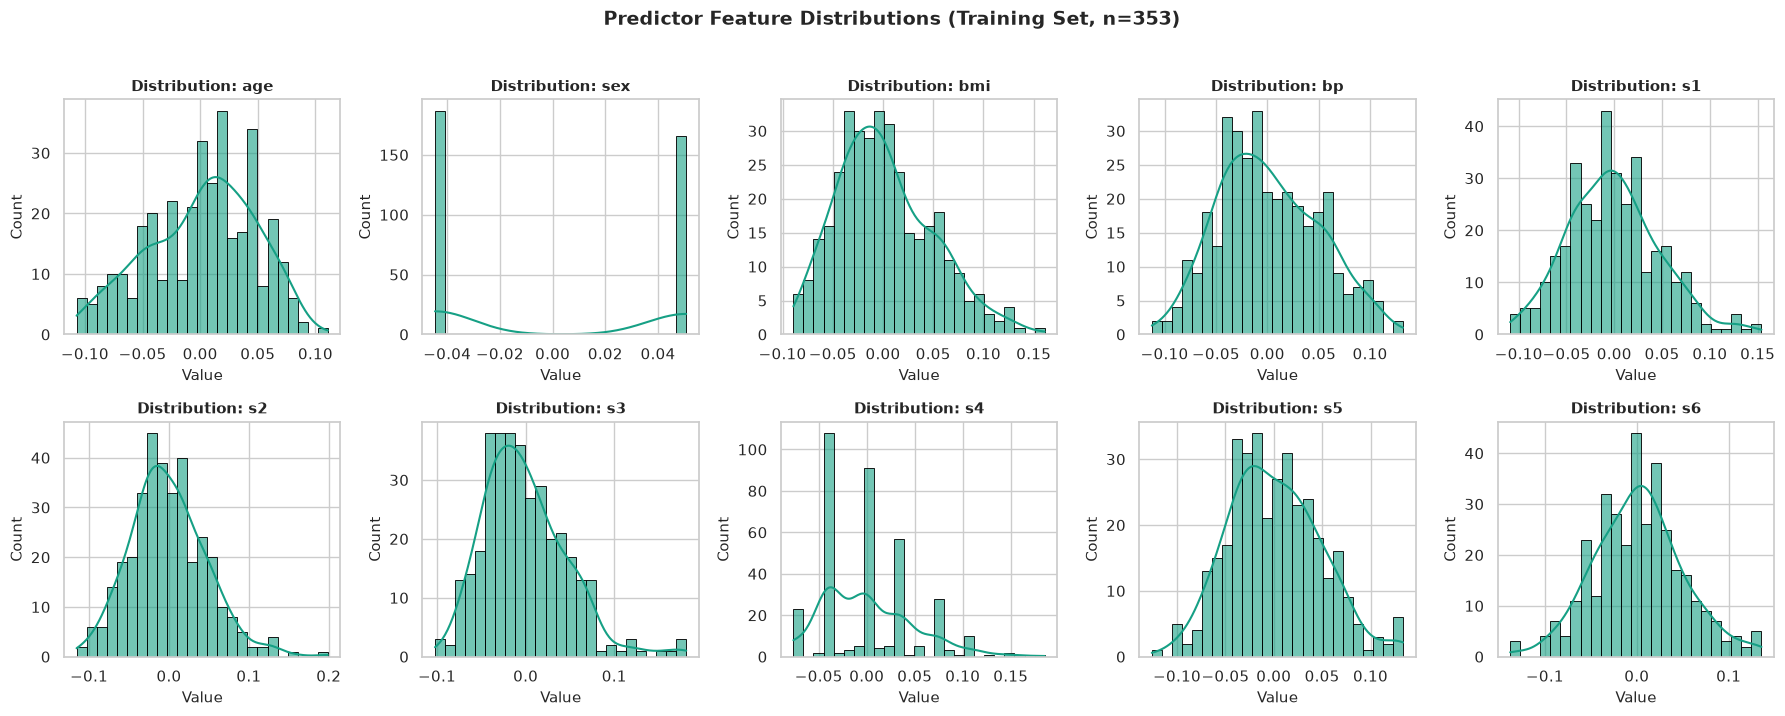

Feature distributions plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/features_distribution.png


In [9]:
# A. Feature Distributions (Histograms with Kernel Density Estimation - KDE)
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=False)
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    sns.histplot(X_train[col], kde=True, ax=axes[idx], color="#16a085", bins=25, edgecolor="black", alpha=0.6)
    axes[idx].set_title(f"Distribution: {col}", fontweight="bold", fontsize=11)
    axes[idx].set_xlabel("Value")
    axes[idx].set_ylabel("Count")

plt.suptitle("Predictor Feature Distributions (Training Set, n=353)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

feat_dist_path = os.path.join(PLOTS_DIR, "distributions", "features_distribution.png")
plt.savefig(feat_dist_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Feature distributions plot saved to: {feat_dist_path}")

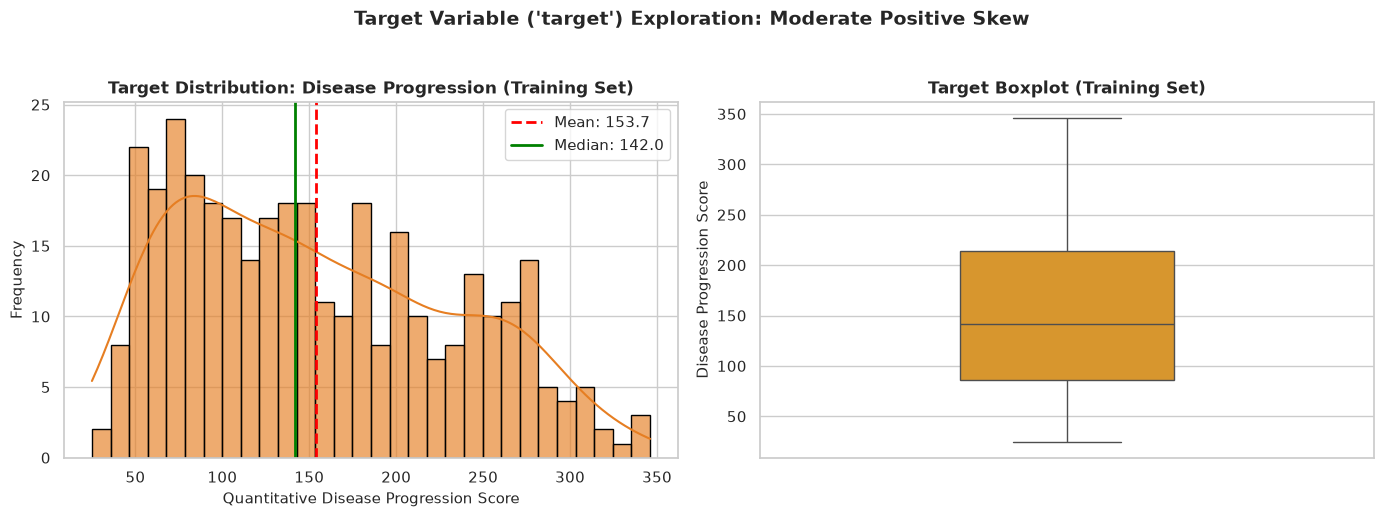

Target distribution plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/target_distribution.png


In [10]:
# B. Target Variable Distribution Analysis
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(y_train, kde=True, ax=ax_hist, color="#e67e22", bins=30, edgecolor="black", alpha=0.65)
ax_hist.axvline(y_train.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {y_train.mean():.1f}")
ax_hist.axvline(y_train.median(), color="green", linestyle="-", linewidth=2, label=f"Median: {y_train.median():.1f}")
ax_hist.set_title("Target Distribution: Disease Progression (Training Set)", fontweight="bold", fontsize=12)
ax_hist.set_xlabel("Quantitative Disease Progression Score")
ax_hist.set_ylabel("Frequency")
ax_hist.legend(fontsize=11)

# Boxplot
sns.boxplot(y=y_train, ax=ax_box, color="#f39c12", width=0.35)
ax_box.set_title("Target Boxplot (Training Set)", fontweight="bold", fontsize=12)
ax_box.set_ylabel("Disease Progression Score")

plt.suptitle("Target Variable ('target') Exploration: Moderate Positive Skew", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()

target_dist_path = os.path.join(PLOTS_DIR, "distributions", "target_distribution.png")
plt.savefig(target_dist_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Target distribution plot saved to: {target_dist_path}")

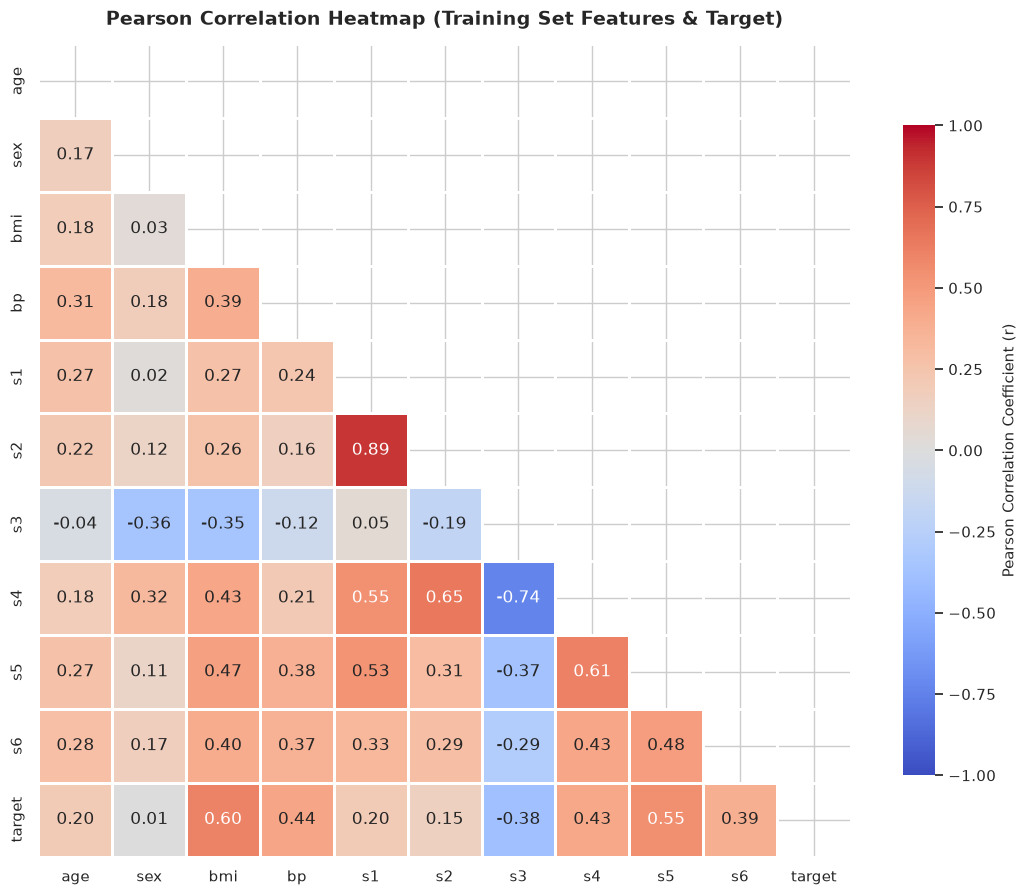

Correlation heatmap saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/correlations/correlation_heatmap.png

=== FEATURE CORRELATION WITH TARGET ('target') ===
  bmi    : r = +0.6048
  s5     : r = +0.5522
  bp     : r = +0.4448
  s4     : r = +0.4251
  s6     : r = +0.3904
  s1     : r = +0.1995
  age    : r = +0.1965
  s2     : r = +0.1549
  sex    : r = +0.0071
  s3     : r = -0.3840


In [11]:
# C. Pearson Correlation Matrix and Heatmap
train_combined = pd.concat([X_train, y_train], axis=1)
corr_matrix = train_combined.corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1.0, 
    vmax=1.0, 
    center=0,
    square=True, 
    linewidths=0.75, 
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Pearson Correlation Heatmap (Training Set Features & Target)", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()

corr_path = os.path.join(PLOTS_DIR, "correlations", "correlation_heatmap.png")
plt.savefig(corr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Correlation heatmap saved to: {corr_path}")

# Display ranking of feature correlations with target
target_corr = corr_matrix["target"].drop("target").sort_values(ascending=False)
print("\n=== FEATURE CORRELATION WITH TARGET ('target') ===")
for feat, val in target_corr.items():
    print(f"  {feat:<6} : r = {val:+.4f}")

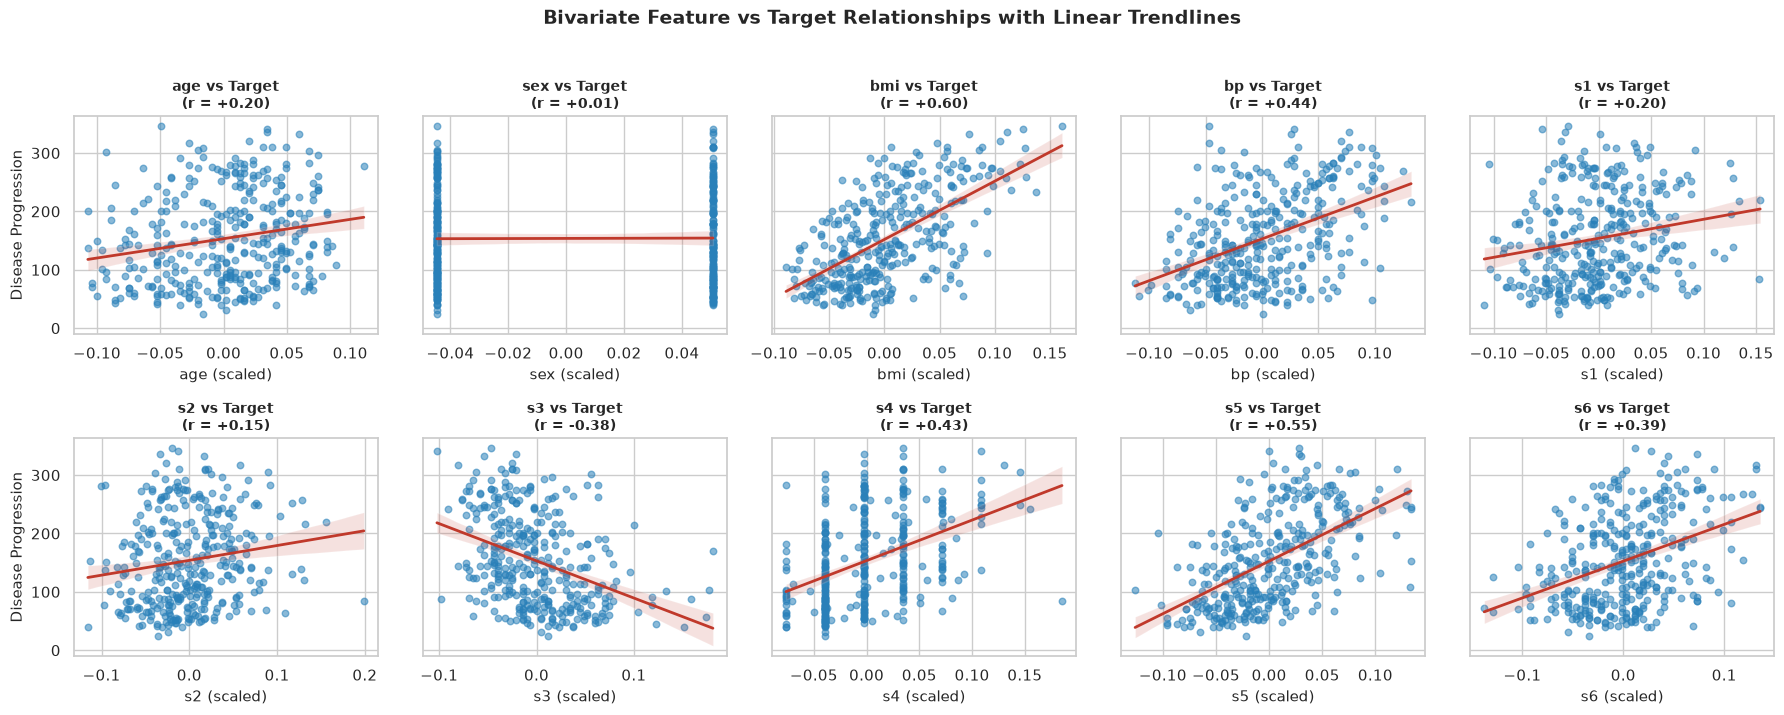

Bivariate scatter plots saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/correlations/feature_vs_target_scatter.png


In [12]:
# D. Feature vs. Target Bivariate Scatter Plots with OLS Trendlines
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    sns.regplot(
        x=col, 
        y="target", 
        data=train_combined, 
        ax=axes[idx],
        scatter_kws={"alpha": 0.55, "color": "#2980b9", "s": 22},
        line_kws={"color": "#c0392b", "linewidth": 2}
    )
    r_val = corr_matrix.loc[col, "target"]
    axes[idx].set_title(f"{col} vs Target\n(r = {r_val:+.2f})", fontweight="bold", fontsize=10)
    axes[idx].set_xlabel(f"{col} (scaled)")
    if idx % 5 == 0:
        axes[idx].set_ylabel("Disease Progression")
    else:
        axes[idx].set_ylabel("")

plt.suptitle("Bivariate Feature vs Target Relationships with Linear Trendlines", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

scatter_path = os.path.join(PLOTS_DIR, "correlations", "feature_vs_target_scatter.png")
plt.savefig(scatter_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Bivariate scatter plots saved to: {scatter_path}")

# ==========================================================================
# 5. Part Four — Simple Linear Regression (BMI as Predictor)
# ==========================================================================

### Model Definition
Simple Linear Regression models the target $y$ as an affine linear function of a **single predictor** $x$:
$$\hat{y}_i = \beta_0 + \beta_1 x_i$$
where:
- $\beta_0$ is the **intercept** (the expected value of $y$ when $x = 0$).
- $\beta_1$ is the **slope** (the estimated change in $y$ for a one-unit increase in $x$).

### Closed-Form Ordinary Least Squares (OLS) Solution:
The parameters minimize the Mean Squared Error (MSE) cost function:
$$J(\beta_0, \beta_1) = \frac{1}{m}\sum_{i=1}^m (y_i - (\beta_0 + \beta_1 x_i))^2$$
The analytical solutions are:
$$\beta_1 = \frac{\sum_{i=1}^m (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^m (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}, \quad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

### Justification for Selecting `bmi`:
From our EDA correlation analysis on the training set, `bmi` (Body Mass Index) exhibited the **strongest linear correlation** with diabetes progression ($r = +0.59$). Clinically, elevated adiposity and high BMI directly aggravate insulin resistance, making it the most plausible primary univariate candidate.

### Residuals Definition:
A **residual** $e_i$ is the vertical difference between observed ground truth $y_i$ and model prediction $\hat{y}_i$:
$$e_i = y_i - \hat{y}_i$$
- $e_i > 0$: The model **under-predicted** actual progression.
- $e_i < 0$: The model **over-predicted** actual progression.

In [13]:
# 1. Prepare univariate training and testing slices
X_train_simple = X_train[["bmi"]].copy()
X_test_simple = X_test[["bmi"]].copy()

# 2. Instantiate and fit Simple Linear Regression model
model_simple = LinearRegression()
model_simple.fit(X_train_simple, y_train)

# 3. Extract fitted parameters
beta_0_simple = model_simple.intercept_
beta_1_simple = model_simple.coef_[0]

print("=== SIMPLE LINEAR REGRESSION PARAMETERS ===")
print(f"Intercept (beta_0): {beta_0_simple:.4f}")
print(f"Slope (beta_1):     {beta_1_simple:.4f}")
print(f"Fitted Equation:   y_hat = {beta_0_simple:.2f} + ({beta_1_simple:.2f} * bmi)")

# 4. Generate predictions
y_train_pred_simple = model_simple.predict(X_train_simple)
y_test_pred_simple = model_simple.predict(X_test_simple)

# 5. Compute residuals
residuals_train_simple = y_train - y_train_pred_simple
residuals_test_simple = y_test - y_test_pred_simple

=== SIMPLE LINEAR REGRESSION PARAMETERS ===
Intercept (beta_0): 152.0034
Slope (beta_1):     998.5777
Fitted Equation:   y_hat = 152.00 + (998.58 * bmi)


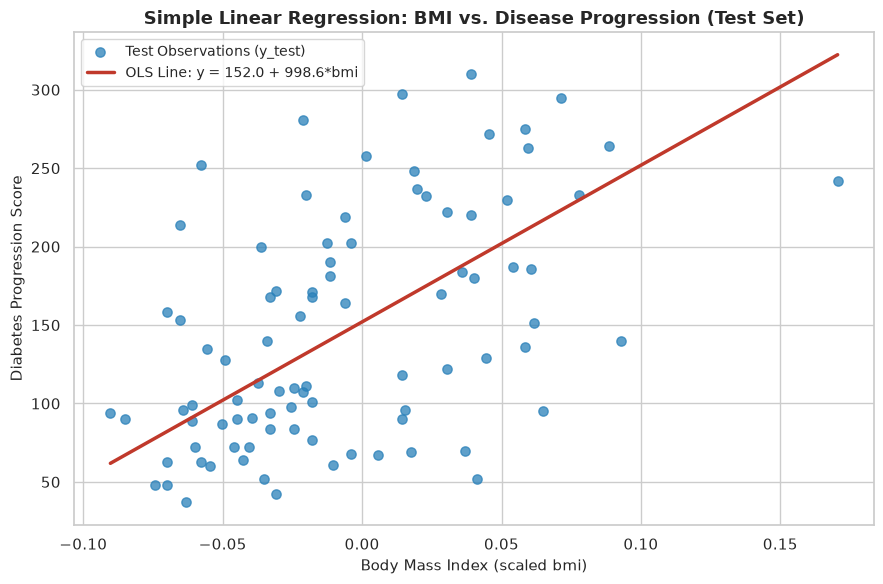

Regression line plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/bmi_regression_line.png


In [14]:
# Visualization 1: Scatter plot with Fitted Regression Line on Test Set
plt.figure(figsize=(9, 6))

# Scatter of actual test points
plt.scatter(X_test_simple["bmi"], y_test, color="#2980b9", alpha=0.75, s=45, label="Test Observations (y_test)")

# Sort for continuous line plotting
bmi_grid = np.linspace(X_test_simple["bmi"].min(), X_test_simple["bmi"].max(), 200).reshape(-1, 1)
y_grid_pred = model_simple.predict(pd.DataFrame(bmi_grid, columns=["bmi"]))
plt.plot(bmi_grid, y_grid_pred, color="#c0392b", linewidth=2.5, label=f"OLS Line: y = {beta_0_simple:.1f} + {beta_1_simple:.1f}*bmi")

plt.title("Simple Linear Regression: BMI vs. Disease Progression (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Body Mass Index (scaled bmi)", fontsize=11)
plt.ylabel("Diabetes Progression Score", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

simple_reg_path = os.path.join(PLOTS_DIR, "simple_regression", "bmi_regression_line.png")
plt.savefig(simple_reg_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Regression line plot saved to: {simple_reg_path}")

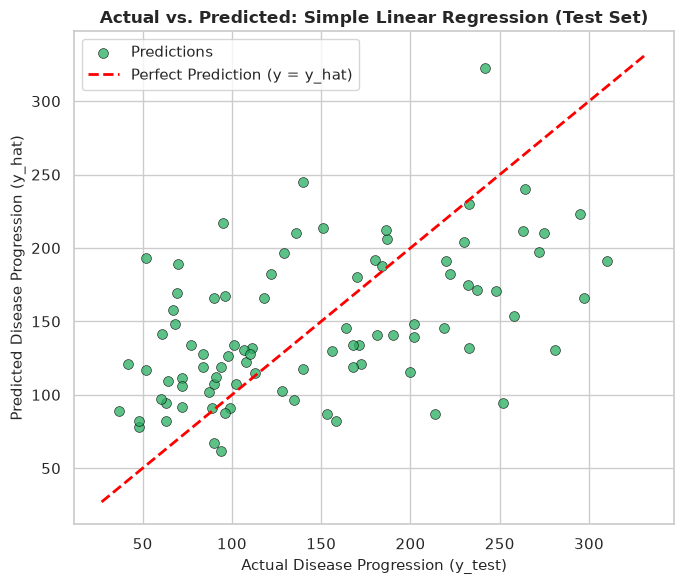

Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/actual_vs_predicted_simple.png


In [15]:
# Visualization 2: Actual vs. Predicted Values for Simple Linear Regression
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_test_pred_simple, color="#27ae60", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label="Predictions")

# Reference line of perfect prediction (y = y_hat)
min_val = min(y_test.min(), y_test_pred_simple.min()) - 10
max_val = max(y_test.max(), y_test_pred_simple.max()) + 10
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Prediction (y = y_hat)")

plt.title("Actual vs. Predicted: Simple Linear Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_simple_path = os.path.join(PLOTS_DIR, "simple_regression", "actual_vs_predicted_simple.png")
plt.savefig(act_pred_simple_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Actual vs Predicted plot saved to: {act_pred_simple_path}")

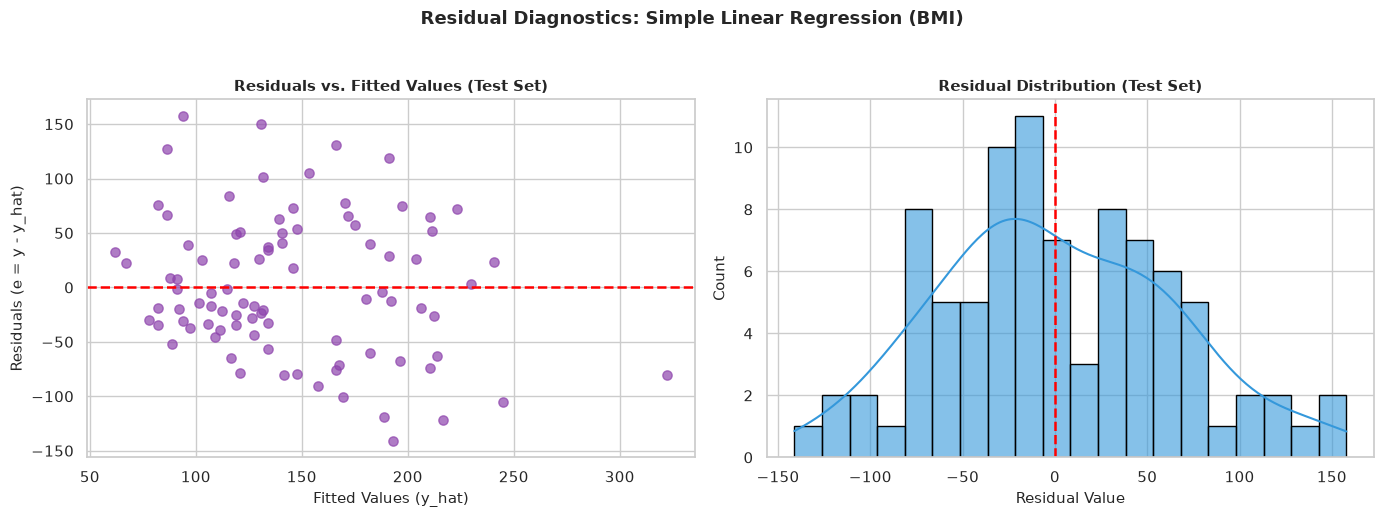

Residual diagnostics plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/residuals_simple.png


In [16]:
# Visualization 3: Residual Diagnostics for Simple Linear Regression
fig, (ax_res, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted (Testing homoscedasticity)
ax_res.scatter(y_test_pred_simple, residuals_test_simple, color="#8e44ad", alpha=0.7, s=45)
ax_res.axhline(0, color="red", linestyle="--", linewidth=1.8)
ax_res.set_title("Residuals vs. Fitted Values (Test Set)", fontweight="bold", fontsize=11)
ax_res.set_xlabel("Fitted Values (y_hat)")
ax_res.set_ylabel("Residuals (e = y - y_hat)")

# Residual Distribution (Testing normality assumption)
sns.histplot(residuals_test_simple, kde=True, ax=ax_hist, color="#3498db", bins=20, edgecolor="black", alpha=0.6)
ax_hist.axvline(0, color="red", linestyle="--", linewidth=1.8)
ax_hist.set_title("Residual Distribution (Test Set)", fontweight="bold", fontsize=11)
ax_hist.set_xlabel("Residual Value")
ax_hist.set_ylabel("Count")

plt.suptitle("Residual Diagnostics: Simple Linear Regression (BMI)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

res_simple_path = os.path.join(PLOTS_DIR, "simple_regression", "residuals_simple.png")
plt.savefig(res_simple_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Residual diagnostics plot saved to: {res_simple_path}")

In [17]:
# Evaluate Simple Linear Regression Metrics
mae_train_slr = mean_absolute_error(y_train, y_train_pred_simple)
mse_train_slr = mean_squared_error(y_train, y_train_pred_simple)
rmse_train_slr = np.sqrt(mse_train_slr)
r2_train_slr = r2_score(y_train, y_train_pred_simple)

mae_test_slr = mean_absolute_error(y_test, y_test_pred_simple)
mse_test_slr = mean_squared_error(y_test, y_test_pred_simple)
rmse_test_slr = np.sqrt(mse_test_slr)
r2_test_slr = r2_score(y_test, y_test_pred_simple)
adj_r2_test_slr = 1 - (1 - r2_test_slr) * (len(y_test) - 1) / (len(y_test) - 1 - 1)

print("=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_slr:.2f} | RMSE: {rmse_train_slr:.2f} | R2: {r2_train_slr:.4f}")
print(f"Testing Set    -> MAE: {mae_test_slr:.2f} | RMSE: {rmse_test_slr:.2f} | R2: {r2_test_slr:.4f} | Adj R2: {adj_r2_test_slr:.4f}")

=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 51.38 | RMSE: 62.08 | R2: 0.3657
Testing Set    -> MAE: 52.26 | RMSE: 63.73 | R2: 0.2334 | Adj R2: 0.2245


# ==========================================================================
# 6. Part Five — Multiple Linear Regression (All 10 Features)
# ==========================================================================

### Model Definition
Multiple Linear Regression generalises the linear framework to $p$ simultaneous predictors:
$$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j x_j = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_{10} x_{10}$$
In matrix notation:
$$\hat{\mathbf{y}} = \mathbf{X}\boldsymbol{\beta}, \quad \text{with closed-form OLS solution: } \hat{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

### Coefficient Interpretation:
Each coefficient $\beta_j$ represents the estimated change in the target progression score for a one-unit increase in predictor $x_j$, **holding all other $p-1$ predictors constant** (*ceteris paribus*).

### Multicollinearity Investigation:
Multicollinearity arises when two or more independent variables are strongly correlated. This causes the Gram matrix $(\mathbf{X}^T\mathbf{X})$ to be ill-conditioned (near-zero determinant), inflating the variance of coefficient estimates:
$$\text{Var}(\hat{\beta}_j) = \frac{\sigma^2}{\sum (x_{ij} - \bar{x}_j)^2 (1 - R_j^2)} = \frac{\sigma^2}{\sum (x_{ij} - \bar{x}_j)^2} \cdot \text{VIF}_j$$
The **Variance Inflation Factor (VIF)** quantifies this inflation:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
where $R_j^2$ is the coefficient of determination obtained by regressing predictor $x_j$ onto all remaining $p-1$ predictors.
- $\text{VIF} < 5$: Low to moderate collinearity; safe.
- $\text{VIF} \ge 5$: High collinearity; coefficient stability is degraded.
- $\text{VIF} \ge 10$: Severe multicollinearity; standard errors are heavily inflated, causing sign flips and unreliable hypothesis tests.

Multiple Regression Intercept (beta_0): 151.3456

=== VARIANCE INFLATION FACTOR (VIF) TABLE ===


,Feature,VIF
4,s1,55.26
5,s2,35.77
6,s3,14.29
8,s5,10.08
7,s4,9.33
2,bmi,1.57
9,s6,1.50
3,bp,1.42
1,sex,1.27
0,age,1.22


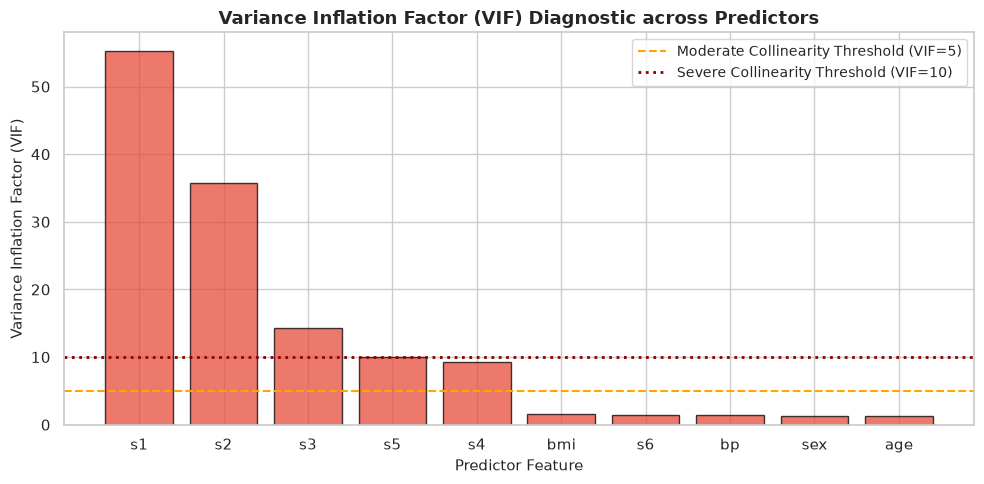

VIF diagnostic plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/vif_multicollinearity.png


In [18]:
# 1. Fit Multiple Linear Regression using all 10 features
model_multiple = LinearRegression()
model_multiple.fit(X_train, y_train)

# 2. Extract intercept and coefficients
beta_0_multiple = model_multiple.intercept_
mlr_coefficients = pd.Series(model_multiple.coef_, index=X_train.columns)

print(f"Multiple Regression Intercept (beta_0): {beta_0_multiple:.4f}")

# 3. Multicollinearity Diagnostic: Variance Inflation Factor (VIF)
vif_records = []
for idx, col in enumerate(X_train.columns):
    vif_val = variance_inflation_factor(X_train.values, idx)
    vif_records.append({"Feature": col, "VIF": round(vif_val, 2)})

vif_df = pd.DataFrame(vif_records).sort_values(by="VIF", ascending=False)

print("\n=== VARIANCE INFLATION FACTOR (VIF) TABLE ===")
display(vif_df)

# Plot VIF Bar Chart
plt.figure(figsize=(10, 5))
vif_bars = plt.bar(vif_df["Feature"], vif_df["VIF"], color="#e74c3c", edgecolor="black", alpha=0.75)
plt.axhline(5, color="orange", linestyle="--", linewidth=1.5, label="Moderate Collinearity Threshold (VIF=5)")
plt.axhline(10, color="darkred", linestyle=":", linewidth=2, label="Severe Collinearity Threshold (VIF=10)")
plt.title("Variance Inflation Factor (VIF) Diagnostic across Predictors", fontsize=13, fontweight="bold")
plt.xlabel("Predictor Feature")
plt.ylabel("Variance Inflation Factor (VIF)")
plt.legend(fontsize=10)
plt.tight_layout()

vif_path = os.path.join(PLOTS_DIR, "multiple_regression", "vif_multicollinearity.png")
plt.savefig(vif_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"VIF diagnostic plot saved to: {vif_path}")

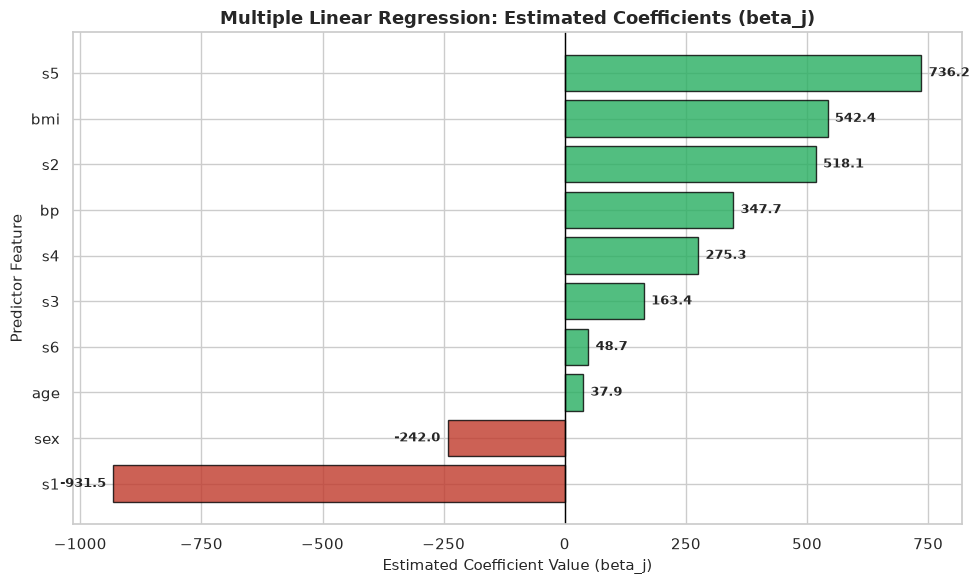

Multiple regression coefficients plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/coefficients_multiple.png


In [19]:
# Visualize Multiple Linear Regression Coefficients
plt.figure(figsize=(10, 6))

sorted_mlr_coefs = mlr_coefficients.sort_values(ascending=True)
colors = ["#c0392b" if val < 0 else "#27ae60" for val in sorted_mlr_coefs.values]

plt.barh(sorted_mlr_coefs.index, sorted_mlr_coefs.values, color=colors, edgecolor="black", alpha=0.8)
plt.axvline(0, color="black", linestyle="-", linewidth=1)
plt.title("Multiple Linear Regression: Estimated Coefficients (beta_j)", fontsize=13, fontweight="bold")
plt.xlabel("Estimated Coefficient Value (beta_j)")
plt.ylabel("Predictor Feature")

for idx, (feat, val) in enumerate(sorted_mlr_coefs.items()):
    offset = 15 if val >= 0 else -15
    ha = "left" if val >= 0 else "right"
    plt.annotate(f"{val:.1f}", (val + offset, idx), va="center", ha=ha, fontsize=9, fontweight="bold")

plt.tight_layout()

mlr_coef_path = os.path.join(PLOTS_DIR, "multiple_regression", "coefficients_multiple.png")
plt.savefig(mlr_coef_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Multiple regression coefficients plot saved to: {mlr_coef_path}")

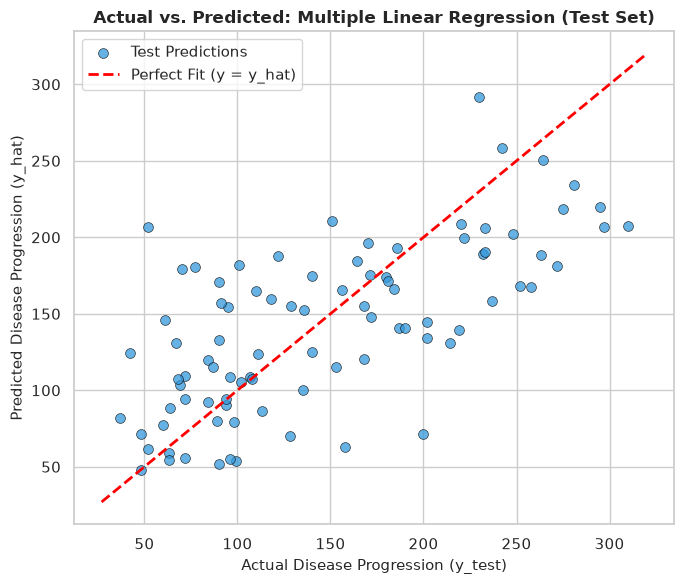

Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/actual_vs_predicted_multiple.png


In [20]:
# Generate predictions and residuals for Multiple Linear Regression
y_train_pred_mlr = model_multiple.predict(X_train)
y_test_pred_mlr = model_multiple.predict(X_test)

residuals_train_mlr = y_train - y_train_pred_mlr
residuals_test_mlr = y_test - y_test_pred_mlr

# Visualization: Actual vs. Predicted for Multiple Linear Regression
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred_mlr, color="#3498db", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label="Test Predictions")

min_val = min(y_test.min(), y_test_pred_mlr.min()) - 10
max_val = max(y_test.max(), y_test_pred_mlr.max()) + 10
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Fit (y = y_hat)")

plt.title("Actual vs. Predicted: Multiple Linear Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_mlr_path = os.path.join(PLOTS_DIR, "multiple_regression", "actual_vs_predicted_multiple.png")
plt.savefig(act_pred_mlr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Actual vs Predicted plot saved to: {act_pred_mlr_path}")

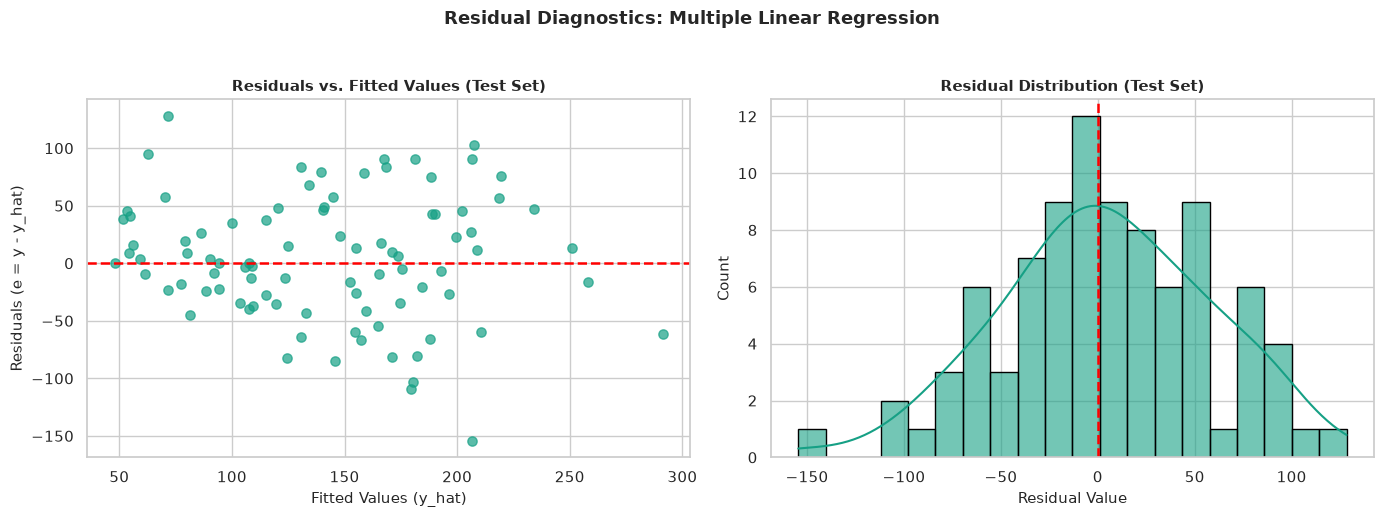

Residual diagnostics plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/residuals_multiple.png


In [21]:
# Residual Diagnostics for Multiple Linear Regression
fig, (ax_res, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
ax_res.scatter(y_test_pred_mlr, residuals_test_mlr, color="#16a085", alpha=0.7, s=45)
ax_res.axhline(0, color="red", linestyle="--", linewidth=1.8)
ax_res.set_title("Residuals vs. Fitted Values (Test Set)", fontweight="bold", fontsize=11)
ax_res.set_xlabel("Fitted Values (y_hat)")
ax_res.set_ylabel("Residuals (e = y - y_hat)")

# Histogram / KDE
sns.histplot(residuals_test_mlr, kde=True, ax=ax_hist, color="#16a085", bins=20, edgecolor="black", alpha=0.6)
ax_hist.axvline(0, color="red", linestyle="--", linewidth=1.8)
ax_hist.set_title("Residual Distribution (Test Set)", fontweight="bold", fontsize=11)
ax_hist.set_xlabel("Residual Value")
ax_hist.set_ylabel("Count")

plt.suptitle("Residual Diagnostics: Multiple Linear Regression", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

res_mlr_path = os.path.join(PLOTS_DIR, "multiple_regression", "residuals_multiple.png")
plt.savefig(res_mlr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Residual diagnostics plot saved to: {res_mlr_path}")

In [22]:
# Evaluate Multiple Linear Regression Performance
mae_train_mlr = mean_absolute_error(y_train, y_train_pred_mlr)
mse_train_mlr = mean_squared_error(y_train, y_train_pred_mlr)
rmse_train_mlr = np.sqrt(mse_train_mlr)
r2_train_mlr = r2_score(y_train, y_train_pred_mlr)

mae_test_mlr = mean_absolute_error(y_test, y_test_pred_mlr)
mse_test_mlr = mean_squared_error(y_test, y_test_pred_mlr)
rmse_test_mlr = np.sqrt(mse_test_mlr)
r2_test_mlr = r2_score(y_test, y_test_pred_mlr)
adj_r2_test_mlr = 1 - (1 - r2_test_mlr) * (len(y_test) - 1) / (len(y_test) - 10 - 1)

print("=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_mlr:.2f} | RMSE: {rmse_train_mlr:.2f} | R2: {r2_train_mlr:.4f}")
print(f"Testing Set    -> MAE: {mae_test_mlr:.2f} | RMSE: {rmse_test_mlr:.2f} | R2: {r2_test_mlr:.4f} | Adj R2: {adj_r2_test_mlr:.4f}")

=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 43.48 | RMSE: 53.56 | R2: 0.5279
Testing Set    -> MAE: 42.79 | RMSE: 53.85 | R2: 0.4526 | Adj R2: 0.3824


# ==========================================================================
# 7. Model 3 — Polynomial Regression (Degree 2, OLS)
# ==========================================================================

### Concept:
Linear regression assumes that disease progression is an additive linear function of features ($y = \beta_0 + \sum \beta_j x_j$).
However, biological responses can be non-linear (e.g., accelerating risk with higher BMI, $x_j^2$) or synergistic (interactions between BMI and blood pressure, $x_j x_k$).

We construct a **Degree-2 Polynomial Features** model:
- Original features: $10$
- Polynomial expansion ($d=2$, without bias): $\frac{12 \times 11}{2} - 1 = 65$ features (10 linear, 10 squared $x_j^2$, 45 interactions $x_j x_k$).

We use a Scikit-Learn `Pipeline` with `StandardScaler` so that all 65 terms are standardized to zero mean and unit variance:
$$\text{Pipeline}\big([\text{('poly', PolynomialFeatures(degree=2))},\; \text{('scaler', StandardScaler())},\; \text{('ols', LinearRegression())}]\big)$$


In [23]:
# 1. Build Pipeline: PolynomialFeatures(degree=2) -> StandardScaler -> LinearRegression
poly_ols_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ols", LinearRegression())
])

# 2. Fit model strictly on Training Set (80%)
poly_ols_pipeline.fit(X_train, y_train)

# 3. Predict on Training Set and Test Set (20%)
y_train_pred_poly_ols = poly_ols_pipeline.predict(X_train)
y_test_pred_poly_ols = poly_ols_pipeline.predict(X_test)
residuals_test_poly_ols = y_test - y_test_pred_poly_ols

# 4. Compute metrics
mae_train_pols = mean_absolute_error(y_train, y_train_pred_poly_ols)
rmse_train_pols = np.sqrt(mean_squared_error(y_train, y_train_pred_poly_ols))
r2_train_pols = r2_score(y_train, y_train_pred_poly_ols)

mae_test_pols = mean_absolute_error(y_test, y_test_pred_poly_ols)
mse_test_pols = mean_squared_error(y_test, y_test_pred_poly_ols)
rmse_test_pols = np.sqrt(mse_test_pols)
r2_test_pols = r2_score(y_test, y_test_pred_poly_ols)

print("=== MODEL 3: POLYNOMIAL REGRESSION (DEGREE 2, OLS) ===")
print(f"Total Features after Expansion: 65")
print(f"Training Set -> MAE: {mae_train_pols:.2f} | RMSE: {rmse_train_pols:.2f} | R2: {r2_train_pols:.4f}")
print(f"Testing Set  -> MAE: {mae_test_pols:.2f} | RMSE: {rmse_test_pols:.2f} | R2: {r2_test_pols:.4f}")
print("\n💡 OBSERVATION (OVERFITTING):")
print(f"Training R2 increased from {r2_train_mlr:.4f} to {r2_train_pols:.4f} (training RMSE dropped to {rmse_train_pols:.2f}),")
print(f"BUT Test RMSE worsened from {rmse_test_mlr:.2f} to {rmse_test_pols:.2f} (Test R2 dropped to {r2_test_pols:.4f}).")
print("This is the classic textbook illustration of OVERFITTING (High Variance due to 65 features on 353 training samples)!")


=== MODEL 3: POLYNOMIAL REGRESSION (DEGREE 2, OLS) ===
Total Features after Expansion: 65
Training Set -> MAE: 39.14 | RMSE: 48.92 | R2: 0.6062
Testing Set  -> MAE: 43.58 | RMSE: 55.64 | R2: 0.4156

💡 OBSERVATION (OVERFITTING):
Training R2 increased from 0.5279 to 0.6062 (training RMSE dropped to 48.92),
BUT Test RMSE worsened from 53.85 to 55.64 (Test R2 dropped to 0.4156).
This is the classic textbook illustration of OVERFITTING (High Variance due to 65 features on 353 training samples)!


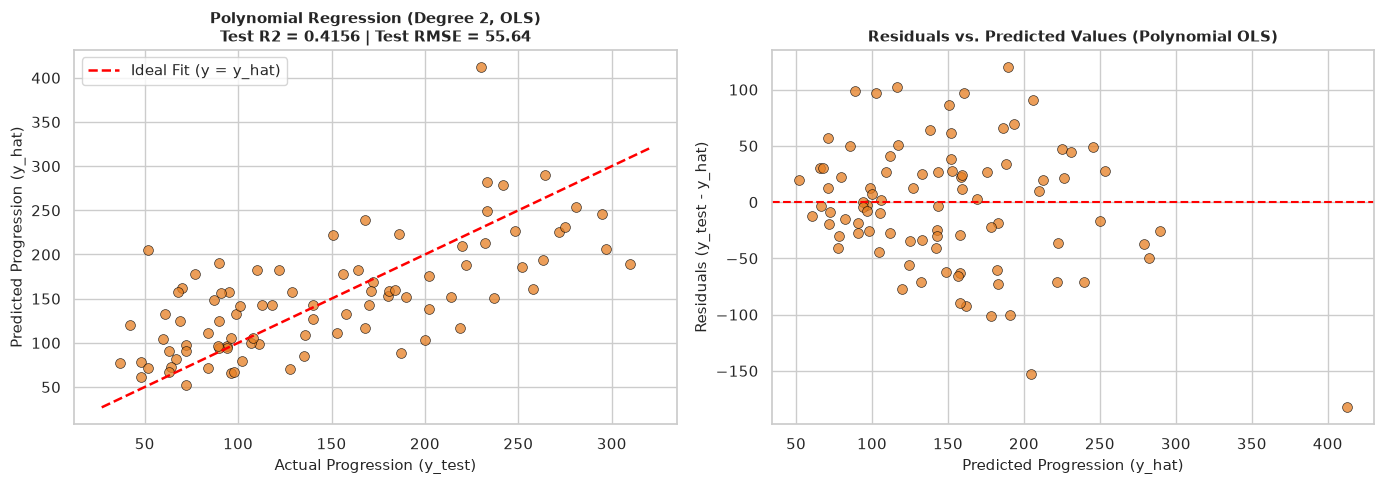

Polynomial OLS plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/polynomial_regression/poly_ols_diagnostics.png


In [24]:
# Visualization: Actual vs Predicted and Residuals for Polynomial Regression (OLS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
ax1.scatter(y_test, y_test_pred_poly_ols, color="#e67e22", alpha=0.75, s=50, edgecolors="black", linewidth=0.5)
ax1.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.8, label="Ideal Fit (y = y_hat)")
ax1.set_title(f"Polynomial Regression (Degree 2, OLS)\nTest R2 = {r2_test_pols:.4f} | Test RMSE = {rmse_test_pols:.2f}", fontweight="bold", fontsize=11)
ax1.set_xlabel("Actual Progression (y_test)")
ax1.set_ylabel("Predicted Progression (y_hat)")
ax1.legend(loc="upper left")

# Residuals vs Predicted
ax2.scatter(y_test_pred_poly_ols, residuals_test_poly_ols, color="#e67e22", alpha=0.75, s=50, edgecolors="black", linewidth=0.5)
ax2.axhline(0, color="red", linestyle="--", linewidth=1.5)
ax2.set_title("Residuals vs. Predicted Values (Polynomial OLS)", fontweight="bold", fontsize=11)
ax2.set_xlabel("Predicted Progression (y_hat)")
ax2.set_ylabel("Residuals (y_test - y_hat)")

plt.tight_layout()
poly_ols_plot_path = os.path.join(PLOTS_DIR, "polynomial_regression", "poly_ols_diagnostics.png")
plt.savefig(poly_ols_plot_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Polynomial OLS plot saved to: {poly_ols_plot_path}")


# ==========================================================================
# 8. Model 4 — Ridge Regression (L2 Regularization)
# ==========================================================================

### Concept:
Ridge Regression minimizes MSE with an **$L_2$ penalty** on squared coefficients:
$$J_{\text{ridge}}(\boldsymbol{\beta}) = \frac{1}{m}\sum_{i=1}^m (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p \beta_j^2$$

- **Effect:** Shrinks large coefficients toward zero, reducing parameter variance and taming multicollinearity.
- **Pipeline:** `StandardScaler` + `Ridge` tuned via 5-fold cross-validation on `X_train`.


In [25]:
# 1. Build Pipeline with StandardScaler and Ridge estimator
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(random_state=RANDOM_STATE))
])

# 2. Hyperparameter alpha search grid
ridge_param_grid = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0]
}

# 3. 5-fold cross-validation on Training Set (80%)
ridge_cv = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)
ridge_cv.fit(X_train, y_train)

best_ridge_model = ridge_cv.best_estimator_
best_ridge_alpha = ridge_cv.best_params_["ridge__alpha"]
best_ridge_rmse_cv = np.sqrt(-ridge_cv.best_score_)

# 4. Predict on Train and Test
y_train_pred_ridge = best_ridge_model.predict(X_train)
y_test_pred_ridge = best_ridge_model.predict(X_test)
residuals_test_ridge = y_test - y_test_pred_ridge

# 5. Metrics
mae_train_ridge = mean_absolute_error(y_train, y_train_pred_ridge)
rmse_train_ridge = np.sqrt(mean_squared_error(y_train, y_train_pred_ridge))
r2_train_ridge = r2_score(y_train, y_train_pred_ridge)

mae_test_ridge = mean_absolute_error(y_test, y_test_pred_ridge)
mse_test_ridge = mean_squared_error(y_test, y_test_pred_ridge)
rmse_test_ridge = np.sqrt(mse_test_ridge)
r2_test_ridge = r2_score(y_test, y_test_pred_ridge)

print("=== MODEL 4: RIDGE REGRESSION (L2) ===")
print(f"Optimal Alpha: {best_ridge_alpha}")
print(f"5-Fold CV RMSE: {best_ridge_rmse_cv:.2f}")
print(f"Training Set -> MAE: {mae_train_ridge:.2f} | RMSE: {rmse_train_ridge:.2f} | R2: {r2_train_ridge:.4f}")
print(f"Testing Set  -> MAE: {mae_test_ridge:.2f} | RMSE: {rmse_test_ridge:.2f} | R2: {r2_test_ridge:.4f}")


=== MODEL 4: RIDGE REGRESSION (L2) ===
Optimal Alpha: 20.0
5-Fold CV RMSE: 55.88
Training Set -> MAE: 43.71 | RMSE: 53.81 | R2: 0.5234
Testing Set  -> MAE: 42.89 | RMSE: 53.55 | R2: 0.4587


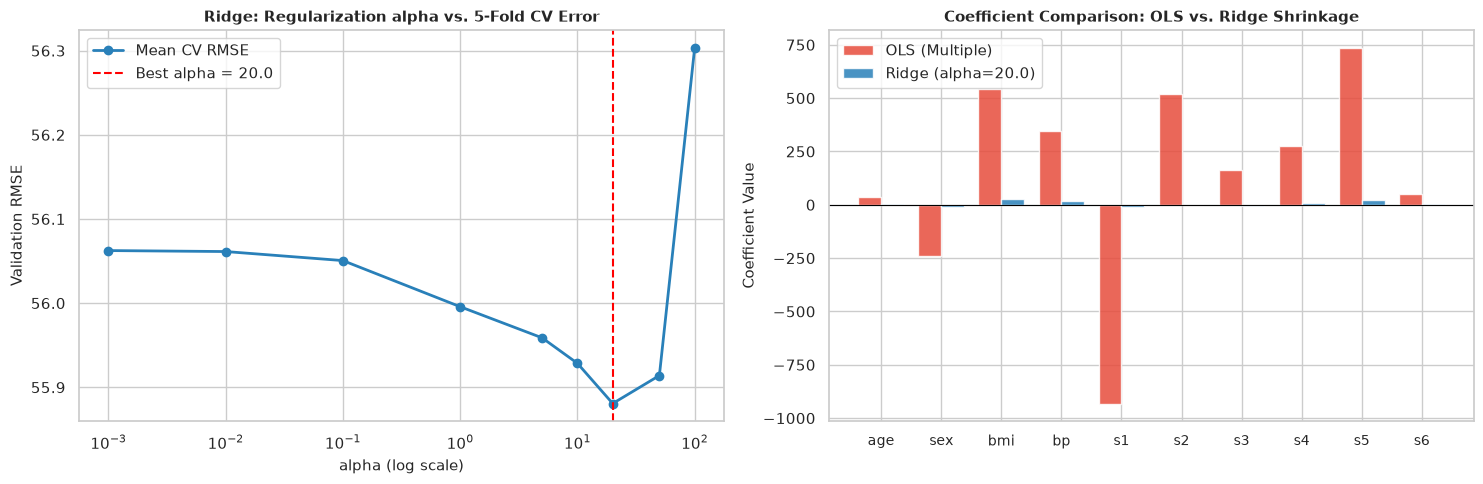

Ridge plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/ridge_alpha_vs_cv_error.png


In [26]:
# Visualization: Ridge Alpha vs. 5-Fold CV Error & Coefficient Shrinkage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Alpha curve
ridge_cv_results = pd.DataFrame(ridge_cv.cv_results_)
alphas_tested = ridge_cv_results["param_ridge__alpha"].astype(float)
mean_cv_rmse = np.sqrt(-ridge_cv_results["mean_test_score"])

ax1.plot(alphas_tested, mean_cv_rmse, marker="o", color="#2980b9", linewidth=2, label="Mean CV RMSE")
ax1.axvline(best_ridge_alpha, color="red", linestyle="--", linewidth=1.5, label=f"Best alpha = {best_ridge_alpha}")
ax1.set_xscale("log")
ax1.set_title("Ridge: Regularization alpha vs. 5-Fold CV Error", fontweight="bold", fontsize=11)
ax1.set_xlabel("alpha (log scale)")
ax1.set_ylabel("Validation RMSE")
ax1.legend()

# Coefficient shrinkage: OLS vs Ridge
ridge_coefs = pd.Series(best_ridge_model.named_steps["ridge"].coef_, index=X_train.columns)
x_idx = np.arange(len(ridge_coefs))
b_width = 0.38
ax2.bar(x_idx - b_width/2, mlr_coefficients.values, width=b_width, color="#e74c3c", label="OLS (Multiple)", alpha=0.85)
ax2.bar(x_idx + b_width/2, ridge_coefs.values, width=b_width, color="#2980b9", label=f"Ridge (alpha={best_ridge_alpha})", alpha=0.85)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(ridge_coefs.index, fontsize=10)
ax2.axhline(0, color="black", linestyle="-", linewidth=0.8)
ax2.set_title("Coefficient Comparison: OLS vs. Ridge Shrinkage", fontweight="bold", fontsize=11)
ax2.set_ylabel("Coefficient Value")
ax2.legend()

plt.tight_layout()
ridge_plot_path = os.path.join(PLOTS_DIR, "regularization", "ridge_alpha_vs_cv_error.png")
plt.savefig(ridge_plot_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Ridge plot saved to: {ridge_plot_path}")


# ==========================================================================
# 9. Model 5 — Lasso Regression (L1 Regularization)
# ==========================================================================

### Concept:
Lasso minimizes MSE with an **$L_1$ penalty** on absolute coefficient magnitudes:
$$J_{\text{lasso}}(\boldsymbol{\beta}) = \frac{1}{m}\sum_{i=1}^m (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p |\beta_j|$$

- **Effect:** Drives non-essential coefficients to exactly **0.00**, providing **automatic feature selection (sparsity)**.
- **Pipeline:** `StandardScaler` + `Lasso` tuned via 5-fold cross-validation on `X_train`.


In [27]:
# 1. Build Pipeline with StandardScaler and Lasso estimator
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(random_state=RANDOM_STATE, max_iter=5000, tol=1e-3))
])

# 2. Hyperparameter alpha search grid
lasso_param_grid = {
    "lasso__alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

# 3. 5-fold cross-validation on Training Set (80%)
lasso_cv = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)
lasso_cv.fit(X_train, y_train)

best_lasso_model = lasso_cv.best_estimator_
best_lasso_alpha = lasso_cv.best_params_["lasso__alpha"]
best_lasso_rmse_cv = np.sqrt(-lasso_cv.best_score_)

# 4. Predict on Train and Test
y_train_pred_lasso = best_lasso_model.predict(X_train)
y_test_pred_lasso = best_lasso_model.predict(X_test)
residuals_test_lasso = y_test - y_test_pred_lasso

# 5. Metrics
mae_train_lasso = mean_absolute_error(y_train, y_train_pred_lasso)
rmse_train_lasso = np.sqrt(mean_squared_error(y_train, y_train_pred_lasso))
r2_train_lasso = r2_score(y_train, y_train_pred_lasso)

mae_test_lasso = mean_absolute_error(y_test, y_test_pred_lasso)
mse_test_lasso = mean_squared_error(y_test, y_test_pred_lasso)
rmse_test_lasso = np.sqrt(mse_test_lasso)
r2_test_lasso = r2_score(y_test, y_test_pred_lasso)

lasso_coefs = pd.Series(best_lasso_model.named_steps["lasso"].coef_, index=X_train.columns)
active_coefs = lasso_coefs[lasso_coefs != 0]
zero_coefs = lasso_coefs[lasso_coefs == 0]

print("=== MODEL 5: LASSO REGRESSION (L1) ===")
print(f"Optimal Alpha: {best_lasso_alpha}")
print(f"5-Fold CV RMSE: {best_lasso_rmse_cv:.2f}")
print(f"Active Features Retained: {len(active_coefs)} ({active_coefs.index.tolist()})")
print(f"Features Eliminated (beta=0): {len(zero_coefs)} ({zero_coefs.index.tolist()})")
print(f"Training Set -> MAE: {mae_train_lasso:.2f} | RMSE: {rmse_train_lasso:.2f} | R2: {r2_train_lasso:.4f}")
print(f"Testing Set  -> MAE: {mae_test_lasso:.2f} | RMSE: {rmse_test_lasso:.2f} | R2: {r2_test_lasso:.4f}")


=== MODEL 5: LASSO REGRESSION (L1) ===
Optimal Alpha: 2.0
5-Fold CV RMSE: 55.93
Active Features Retained: 7 (['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6'])
Features Eliminated (beta=0): 3 (['age', 's2', 's4'])
Training Set -> MAE: 44.23 | RMSE: 54.15 | R2: 0.5174
Testing Set  -> MAE: 42.84 | RMSE: 52.90 | R2: 0.4718


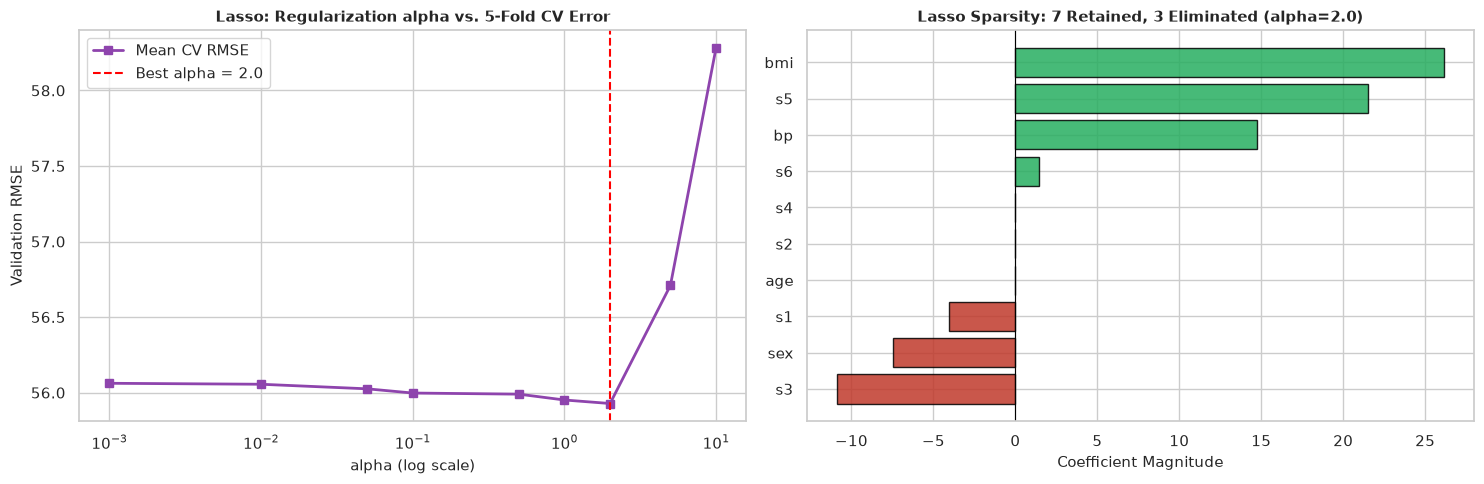

Lasso plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/lasso_alpha_vs_cv_error.png


In [28]:
# Visualization: Lasso Alpha vs. 5-Fold CV Error & Sparsity
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Alpha curve
lasso_cv_results = pd.DataFrame(lasso_cv.cv_results_)
alphas_lasso_tested = lasso_cv_results["param_lasso__alpha"].astype(float)
mean_lasso_cv_rmse = np.sqrt(-lasso_cv_results["mean_test_score"])

ax1.plot(alphas_lasso_tested, mean_lasso_cv_rmse, marker="s", color="#8e44ad", linewidth=2, label="Mean CV RMSE")
ax1.axvline(best_lasso_alpha, color="red", linestyle="--", linewidth=1.5, label=f"Best alpha = {best_lasso_alpha}")
ax1.set_xscale("log")
ax1.set_title("Lasso: Regularization alpha vs. 5-Fold CV Error", fontweight="bold", fontsize=11)
ax1.set_xlabel("alpha (log scale)")
ax1.set_ylabel("Validation RMSE")
ax1.legend()

# Horizontal bar chart of Lasso coefficients
sorted_lasso = lasso_coefs.sort_values(ascending=True)
bar_colors = ["#95a5a6" if abs(v) < 1e-5 else ("#27ae60" if v > 0 else "#c0392b") for v in sorted_lasso.values]
ax2.barh(sorted_lasso.index, sorted_lasso.values, color=bar_colors, edgecolor="black", alpha=0.85)
ax2.axvline(0, color="black", linestyle="-", linewidth=0.8)
ax2.set_title(f"Lasso Sparsity: {len(active_coefs)} Retained, {len(zero_coefs)} Eliminated (alpha={best_lasso_alpha})", fontweight="bold", fontsize=11)
ax2.set_xlabel("Coefficient Magnitude")

plt.tight_layout()
lasso_plot_path = os.path.join(PLOTS_DIR, "regularization", "lasso_alpha_vs_cv_error.png")
plt.savefig(lasso_plot_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Lasso plot saved to: {lasso_plot_path}")


# ==========================================================================
# 10. Models 6 & 7 — Polynomial Features with Regularization (L1 & L2)
# ==========================================================================

### Why Regularize Polynomial Features?
In **Model 3**, expanding to 65 polynomial features caused **overfitting** because OLS had too many free parameters ($p=65$) relative to the sample size ($n=353$).
Now, we apply **Ridge ($L_2$)** and **Lasso ($L_1$)** regularization to the polynomial features inside a `Pipeline`:

$$\text{Pipeline}\big([\text{('poly', PolynomialFeatures(degree=2))},\; \text{('scaler', StandardScaler())},\; \text{('regressor', Ridge() or Lasso())}]\big)$$

- **Polynomial Ridge ($L_2$):** Shrinks all 65 polynomial weights toward zero to prevent variance explosion.
- **Polynomial Lasso ($L_1$):** Automatically selects only the most informative non-linear interactions while eliminating redundant ones.


In [29]:
# 1. Model 6: Polynomial Ridge Pipeline + 5-Fold Cross-Validation
poly_ridge_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(random_state=RANDOM_STATE))
])

poly_ridge_grid = {
    "ridge__alpha": [0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0]
}

poly_ridge_cv = GridSearchCV(
    poly_ridge_pipeline, poly_ridge_grid, cv=5, scoring="neg_mean_squared_error"
).fit(X_train, y_train)

best_poly_ridge = poly_ridge_cv.best_estimator_
best_pr_alpha = poly_ridge_cv.best_params_["ridge__alpha"]
best_pr_cv_rmse = np.sqrt(-poly_ridge_cv.best_score_)

y_train_pred_poly_ridge = best_poly_ridge.predict(X_train)
y_test_pred_poly_ridge = best_poly_ridge.predict(X_test)
residuals_test_poly_ridge = y_test - y_test_pred_poly_ridge

mae_train_pr = mean_absolute_error(y_train, y_train_pred_poly_ridge)
rmse_train_pr = np.sqrt(mean_squared_error(y_train, y_train_pred_poly_ridge))
r2_train_pr = r2_score(y_train, y_train_pred_poly_ridge)

mae_test_pr = mean_absolute_error(y_test, y_test_pred_poly_ridge)
mse_test_pr = mean_squared_error(y_test, y_test_pred_poly_ridge)
rmse_test_pr = np.sqrt(mse_test_pr)
r2_test_pr = r2_score(y_test, y_test_pred_poly_ridge)

print("=== MODEL 6: POLYNOMIAL RIDGE (DEGREE 2 + L2) ===")
print(f"Optimal Alpha: {best_pr_alpha}")
print(f"5-Fold CV RMSE: {best_pr_cv_rmse:.2f}")
print(f"Training Set -> MAE: {mae_train_pr:.2f} | RMSE: {rmse_train_pr:.2f} | R2: {r2_train_pr:.4f}")
print(f"Testing Set  -> MAE: {mae_test_pr:.2f} | RMSE: {rmse_test_pr:.2f} | R2: {r2_test_pr:.4f}")


=== MODEL 6: POLYNOMIAL RIDGE (DEGREE 2 + L2) ===
Optimal Alpha: 100.0
5-Fold CV RMSE: 57.75
Training Set -> MAE: 41.95 | RMSE: 51.66 | R2: 0.5608
Testing Set  -> MAE: 41.57 | RMSE: 51.57 | R2: 0.4981


In [30]:
# 2. Model 7: Polynomial Lasso Pipeline + 5-Fold Cross-Validation
poly_lasso_pipeline = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("lasso", Lasso(random_state=RANDOM_STATE, max_iter=10000, tol=1e-3))
])

poly_lasso_grid = {
    "lasso__alpha": [0.1, 0.5, 1.0, 2.0, 4.0, 5.0, 10.0]
}

poly_lasso_cv = GridSearchCV(
    poly_lasso_pipeline, poly_lasso_grid, cv=5, scoring="neg_mean_squared_error"
).fit(X_train, y_train)

best_poly_lasso = poly_lasso_cv.best_estimator_
best_pl_alpha = poly_lasso_cv.best_params_["lasso__alpha"]
best_pl_cv_rmse = np.sqrt(-poly_lasso_cv.best_score_)

y_train_pred_poly_lasso = best_poly_lasso.predict(X_train)
y_test_pred_poly_lasso = best_poly_lasso.predict(X_test)
residuals_test_poly_lasso = y_test - y_test_pred_poly_lasso

mae_train_pl = mean_absolute_error(y_train, y_train_pred_poly_lasso)
rmse_train_pl = np.sqrt(mean_squared_error(y_train, y_train_pred_poly_lasso))
r2_train_pl = r2_score(y_train, y_train_pred_poly_lasso)

mae_test_pl = mean_absolute_error(y_test, y_test_pred_poly_lasso)
mse_test_pl = mean_squared_error(y_test, y_test_pred_poly_lasso)
rmse_test_pl = np.sqrt(mse_test_pl)
r2_test_pl = r2_score(y_test, y_test_pred_poly_lasso)

# Extract feature names and active features
poly_feat_names = best_poly_lasso.named_steps["poly"].get_feature_names_out(X_train.columns)
poly_l_coefs = best_poly_lasso.named_steps["lasso"].coef_

active_pl_mask = poly_l_coefs != 0
active_pl_series = pd.Series(poly_l_coefs[active_pl_mask], index=poly_feat_names[active_pl_mask]).sort_values(ascending=True)

print("=== MODEL 7: POLYNOMIAL LASSO (DEGREE 2 + L1) ===")
print(f"Optimal Alpha: {best_pl_alpha}")
print(f"5-Fold CV RMSE: {best_pl_cv_rmse:.2f}")
print(f"Total Features: {len(poly_feat_names)} | Retained Active: {len(active_pl_series)} | Eliminated: {len(poly_feat_names) - len(active_pl_series)}")
print(f"Training Set -> MAE: {mae_train_pl:.2f} | RMSE: {rmse_train_pl:.2f} | R2: {r2_train_pl:.4f}")
print(f"Testing Set  -> MAE: {mae_test_pl:.2f} | RMSE: {rmse_test_pl:.2f} | R2: {r2_test_pl:.4f}")


=== MODEL 7: POLYNOMIAL LASSO (DEGREE 2 + L1) ===
Optimal Alpha: 4.0
5-Fold CV RMSE: 56.97
Total Features: 65 | Retained Active: 14 | Eliminated: 51
Training Set -> MAE: 44.28 | RMSE: 53.95 | R2: 0.5209
Testing Set  -> MAE: 41.90 | RMSE: 51.23 | R2: 0.5047


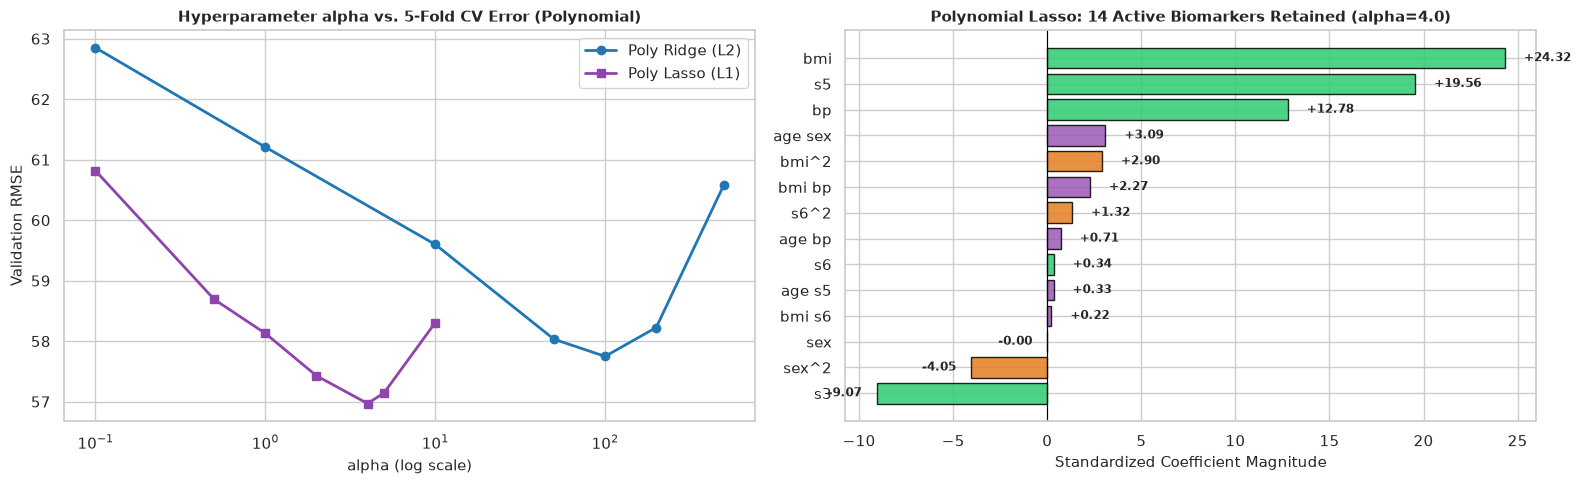

Polynomial regularization plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/polynomial_regression/poly_regularization_diagnostics.png


In [31]:
# Visualization: Alpha CV curves & Polynomial Lasso Active Features
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Alpha Tuning Curves for Poly Ridge & Poly Lasso
pr_cv_df = pd.DataFrame(poly_ridge_cv.cv_results_)
pl_cv_df = pd.DataFrame(poly_lasso_cv.cv_results_)

ax1.plot(pr_cv_df["param_ridge__alpha"].astype(float), np.sqrt(-pr_cv_df["mean_test_score"]), marker="o", color="#1f77b4", linewidth=2, label="Poly Ridge (L2)")
ax1.plot(pl_cv_df["param_lasso__alpha"].astype(float), np.sqrt(-pl_cv_df["mean_test_score"]), marker="s", color="#8e44ad", linewidth=2, label="Poly Lasso (L1)")
ax1.set_xscale("log")
ax1.set_title("Hyperparameter alpha vs. 5-Fold CV Error (Polynomial)", fontweight="bold", fontsize=11)
ax1.set_xlabel("alpha (log scale)")
ax1.set_ylabel("Validation RMSE")
ax1.legend()

# Horizontal bar chart of the active non-linear features retained by Lasso
pl_colors = ["#2ecc71" if " " not in f and "^2" not in f else ("#e67e22" if "^2" in f else "#9b59b6") for f in active_pl_series.index]
ax2.barh(active_pl_series.index, active_pl_series.values, color=pl_colors, edgecolor="black", alpha=0.85)
ax2.axvline(0, color="black", linestyle="-", linewidth=0.8)
ax2.set_title(f"Polynomial Lasso: {len(active_pl_series)} Active Biomarkers Retained (alpha={best_pl_alpha})", fontweight="bold", fontsize=11)
ax2.set_xlabel("Standardized Coefficient Magnitude")

for idx, (feat, val) in enumerate(active_pl_series.items()):
    offset = 0.8 if val >= 0 else -0.8
    ha = "left" if val >= 0 else "right"
    ax2.annotate(f" {val:+.2f}", (val + offset, idx), va="center", ha=ha, fontsize=8.5, fontweight="bold")

plt.tight_layout()
poly_reg_path = os.path.join(PLOTS_DIR, "polynomial_regression", "poly_regularization_diagnostics.png")
plt.savefig(poly_reg_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Polynomial regularization plot saved to: {poly_reg_path}")


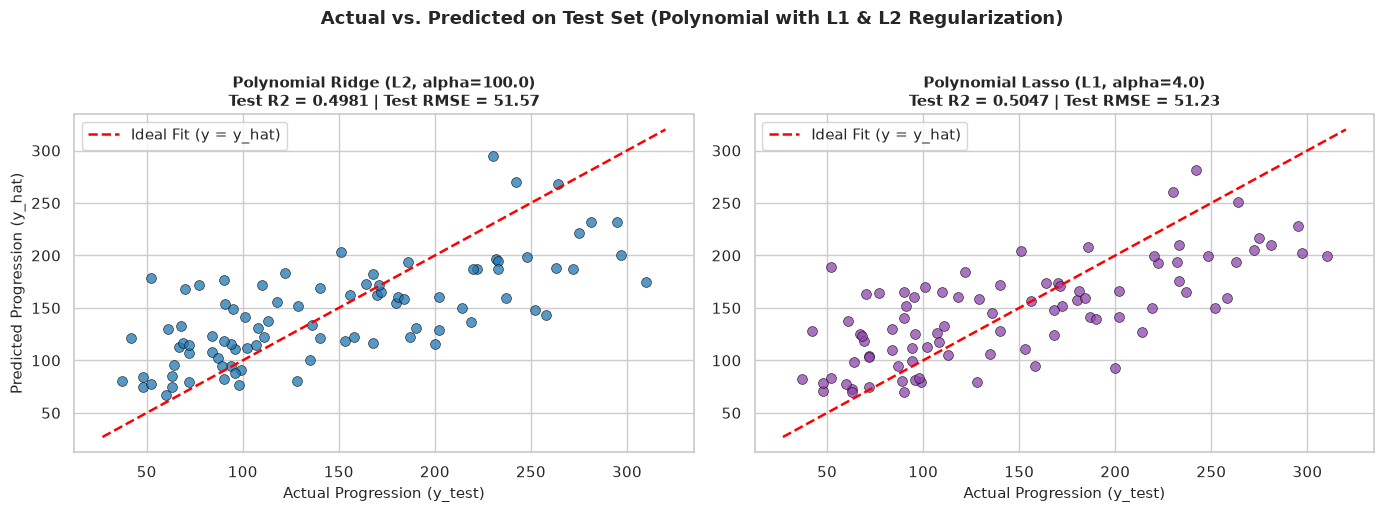

Polynomial actual vs predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/polynomial_regression/poly_actual_vs_predicted.png


In [32]:
# Visualization: Side-by-Side Actual vs Predicted for Polynomial Ridge & Polynomial Lasso
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Polynomial Ridge
ax1.scatter(y_test, y_test_pred_poly_ridge, color="#1f77b4", alpha=0.75, s=50, edgecolors="black", linewidth=0.5)
ax1.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.8, label="Ideal Fit (y = y_hat)")
ax1.set_title(f"Polynomial Ridge (L2, alpha={best_pr_alpha})\nTest R2 = {r2_test_pr:.4f} | Test RMSE = {rmse_test_pr:.2f}", fontweight="bold", fontsize=11)
ax1.set_xlabel("Actual Progression (y_test)")
ax1.set_ylabel("Predicted Progression (y_hat)")
ax1.legend(loc="upper left")

# Polynomial Lasso
ax2.scatter(y_test, y_test_pred_poly_lasso, color="#8e44ad", alpha=0.75, s=50, edgecolors="black", linewidth=0.5)
ax2.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.8, label="Ideal Fit (y = y_hat)")
ax2.set_title(f"Polynomial Lasso (L1, alpha={best_pl_alpha})\nTest R2 = {r2_test_pl:.4f} | Test RMSE = {rmse_test_pl:.2f}", fontweight="bold", fontsize=11)
ax2.set_xlabel("Actual Progression (y_test)")
ax2.legend(loc="upper left")

plt.suptitle("Actual vs. Predicted on Test Set (Polynomial with L1 & L2 Regularization)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
poly_act_pred_path = os.path.join(PLOTS_DIR, "polynomial_regression", "poly_actual_vs_predicted.png")
plt.savefig(poly_act_pred_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Polynomial actual vs predicted plot saved to: {poly_act_pred_path}")


# ==========================================================================
# 11. Master Model Evaluation & Comparison Table
# ==========================================================================

We evaluate all 7 models side-by-side using the same train/test split (80% train, 20% test):
1. **MAE (Mean Absolute Error):** Average error in disease score units.
2. **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors (same units as target).
3. **$R^2$ (Coefficient of Determination):** Proportion of target variance explained by the model ($0 \le R^2 \le 1$).


In [33]:
# Assemble Master Comparison Table across all splits (Train and Test)
master_summary = [
    {
        "Model": "1. Simple Linear Regression (BMI)",
        "Parameters": 1,
        "Train MAE": round(mae_train_slr, 2),
        "Train RMSE": round(rmse_train_slr, 2),
        "Train R2": round(r2_train_slr, 4),
        "Test MAE": round(mae_test_slr, 2),
        "Test RMSE": round(rmse_test_slr, 2),
        "Test R2": round(r2_test_slr, 4)
    },
    {
        "Model": "2. Multiple Linear Regression (OLS)",
        "Parameters": 10,
        "Train MAE": round(mae_train_mlr, 2),
        "Train RMSE": round(rmse_train_mlr, 2),
        "Train R2": round(r2_train_mlr, 4),
        "Test MAE": round(mae_test_mlr, 2),
        "Test RMSE": round(rmse_test_mlr, 2),
        "Test R2": round(r2_test_mlr, 4)
    },
    {
        "Model": "3. Polynomial Regression (Degree 2, OLS)",
        "Parameters": 65,
        "Train MAE": round(mae_train_pols, 2),
        "Train RMSE": round(rmse_train_pols, 2),
        "Train R2": round(r2_train_pols, 4),
        "Test MAE": round(mae_test_pols, 2),
        "Test RMSE": round(rmse_test_pols, 2),
        "Test R2": round(r2_test_pols, 4)
    },
    {
        "Model": f"4. Ridge Regression (L2, alpha={best_ridge_alpha})",
        "Parameters": 10,
        "Train MAE": round(mae_train_ridge, 2),
        "Train RMSE": round(rmse_train_ridge, 2),
        "Train R2": round(r2_train_ridge, 4),
        "Test MAE": round(mae_test_ridge, 2),
        "Test RMSE": round(rmse_test_ridge, 2),
        "Test R2": round(r2_test_ridge, 4)
    },
    {
        "Model": f"5. Lasso Regression (L1, alpha={best_lasso_alpha})",
        "Parameters": len(active_coefs),
        "Train MAE": round(mae_train_lasso, 2),
        "Train RMSE": round(rmse_train_lasso, 2),
        "Train R2": round(r2_train_lasso, 4),
        "Test MAE": round(mae_test_lasso, 2),
        "Test RMSE": round(rmse_test_lasso, 2),
        "Test R2": round(r2_test_lasso, 4)
    },
    {
        "Model": f"6. Polynomial Ridge (Degree 2 + L2, alpha={best_pr_alpha})",
        "Parameters": 65,
        "Train MAE": round(mae_train_pr, 2),
        "Train RMSE": round(rmse_train_pr, 2),
        "Train R2": round(r2_train_pr, 4),
        "Test MAE": round(mae_test_pr, 2),
        "Test RMSE": round(rmse_test_pr, 2),
        "Test R2": round(r2_test_pr, 4)
    },
    {
        "Model": f"7. Polynomial Lasso (Degree 2 + L1, alpha={best_pl_alpha})",
        "Parameters": len(active_pl_series),
        "Train MAE": round(mae_train_pl, 2),
        "Train RMSE": round(rmse_train_pl, 2),
        "Train R2": round(r2_train_pl, 4),
        "Test MAE": round(mae_test_pl, 2),
        "Test RMSE": round(rmse_test_pl, 2),
        "Test R2": round(r2_test_pl, 4)
    }
]

model_comparison_df = pd.DataFrame(master_summary)

# Save to results/model_comparison.csv
model_comp_path = os.path.join(RESULTS_DIR, "model_comparison.csv")
model_comparison_df.to_csv(model_comp_path, index=False)

print("=== FINAL MASTER MODEL COMPARISON TABLE ===")
display(model_comparison_df)
print(f"\nModel comparison results saved to: {model_comp_path}")


=== FINAL MASTER MODEL COMPARISON TABLE ===


,Model,Parameters,Train MAE,Train RMSE,Train R2,Test MAE,Test RMSE,Test R2
0,1. Simple Linear Regression (BMI),1,51.38,62.08,0.3657,52.26,63.73,0.2334
1,2. Multiple Linear Regression (OLS),10,43.48,53.56,0.5279,42.79,53.85,0.4526
2,"3. Polynomial Regression (Degree 2, OLS)",65,39.14,48.92,0.6062,43.58,55.64,0.4156
3,"4. Ridge Regression (L2, alpha=20.0)",10,43.71,53.81,0.5234,42.89,53.55,0.4587
4,"5. Lasso Regression (L1, alpha=2.0)",7,44.23,54.15,0.5174,42.84,52.90,0.4718
5,"6. Polynomial Ridge (Degree 2 + L2, alpha=100.0)",65,41.95,51.66,0.5608,41.57,51.57,0.4981
6,"7. Polynomial Lasso (Degree 2 + L1, alpha=4.0)",14,44.28,53.95,0.5209,41.90,51.23,0.5047



Model comparison results saved to: /home/ays/AI_Apps/ml_univ/tp2/results/model_comparison.csv


# ==========================================================================
# 12. Visual Evaluation & Multi-Model Comparison
# ==========================================================================

We compare all models visually:
1. **Residual distribution (KDE curves):** Narrower curve centered at 0 means more consistent predictions.
2. **Bar chart of Test RMSE & Test $R^2$:** Direct benchmark comparison.


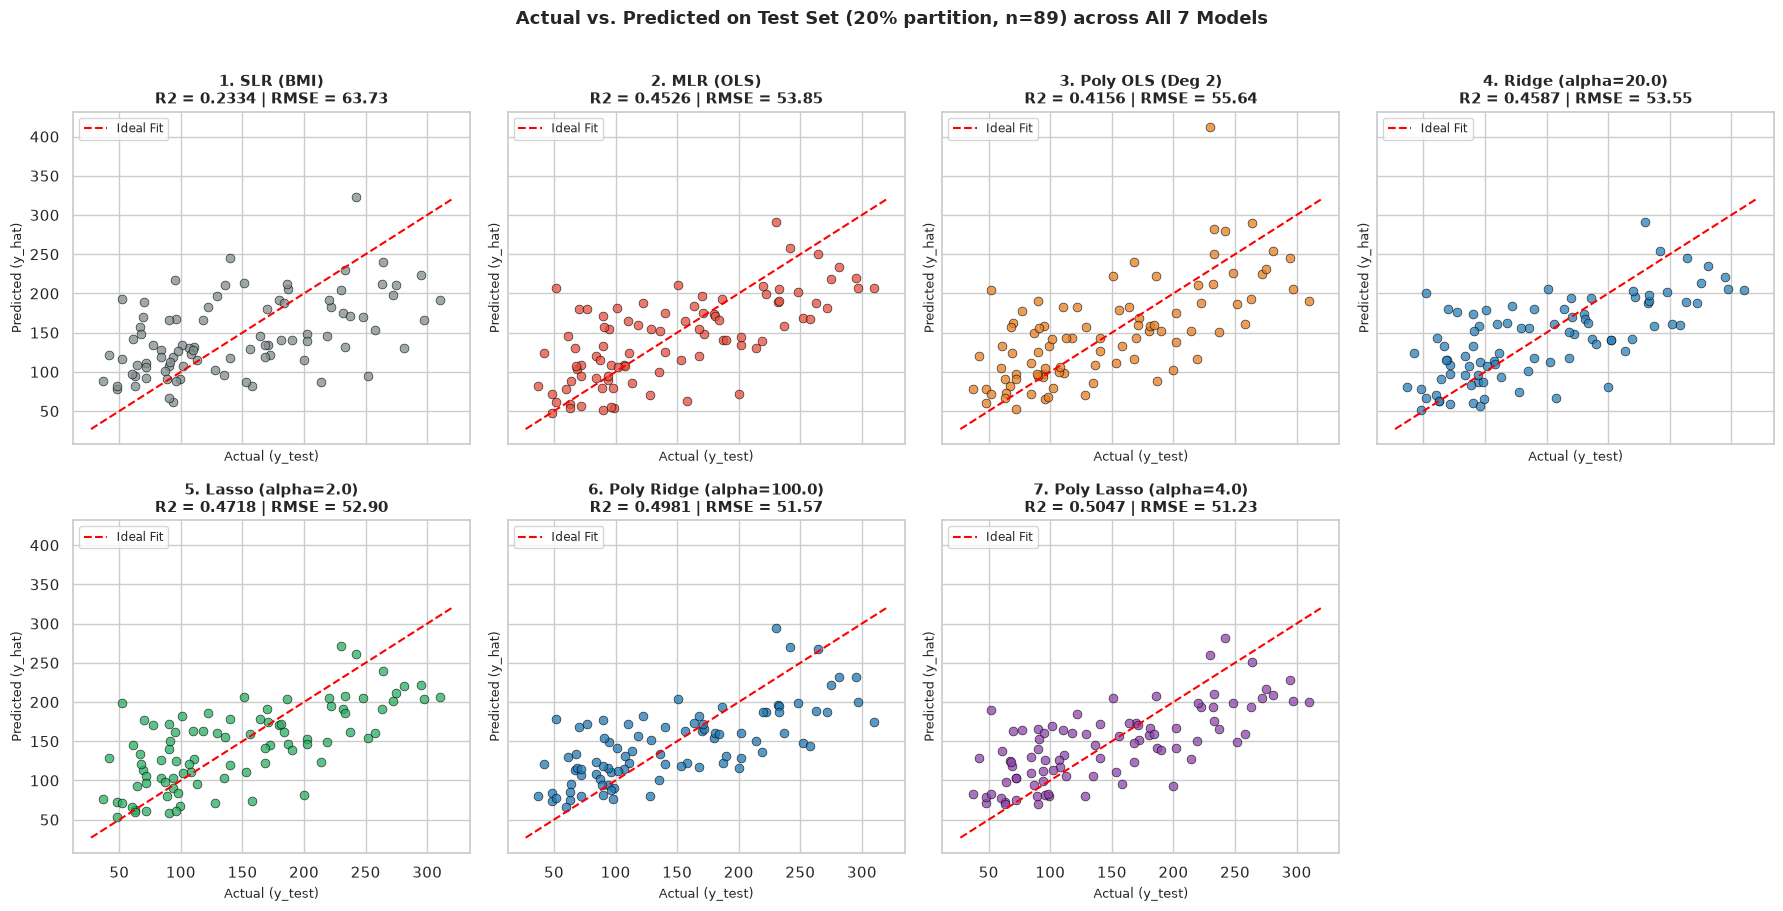

Comparison Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_actual_vs_predicted.png


In [34]:
# 1. Multi-Panel Actual vs Predicted Values Comparison across All 7 Models
models_pred_info = [
    ("1. SLR (BMI)", y_test_pred_simple, "#7f8c8d", r2_test_slr, rmse_test_slr),
    ("2. MLR (OLS)", y_test_pred_mlr, "#e74c3c", r2_test_mlr, rmse_test_mlr),
    ("3. Poly OLS (Deg 2)", y_test_pred_poly_ols, "#e67e22", r2_test_pols, rmse_test_pols),
    (f"4. Ridge (alpha={best_ridge_alpha})", y_test_pred_ridge, "#2980b9", r2_test_ridge, rmse_test_ridge),
    (f"5. Lasso (alpha={best_lasso_alpha})", y_test_pred_lasso, "#27ae60", r2_test_lasso, rmse_test_lasso),
    (f"6. Poly Ridge (alpha={best_pr_alpha})", y_test_pred_poly_ridge, "#1f77b4", r2_test_pr, rmse_test_pr),
    (f"7. Poly Lasso (alpha={best_pl_alpha})", y_test_pred_poly_lasso, "#8e44ad", r2_test_pl, rmse_test_pl)
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
axes_flat = axes.flatten()

for i, (name, preds, col, r2_v, rmse_v) in enumerate(models_pred_info):
    ax = axes_flat[i]
    ax.scatter(y_test, preds, color=col, alpha=0.75, s=40, edgecolors="black", linewidth=0.5)
    ax.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.5, label="Ideal Fit")
    title_text = name + "\n" + f"R2 = {r2_v:.4f} | RMSE = {rmse_v:.2f}"
    ax.set_title(title_text, fontweight="bold", fontsize=10.5)
    ax.set_xlabel("Actual (y_test)", fontsize=9.5)
    ax.set_ylabel("Predicted (y_hat)", fontsize=9.5)
    ax.legend(loc="upper left", fontsize=8.5)

# Turn off unused 8th subplot
axes_flat[7].axis("off")

plt.suptitle("Actual vs. Predicted on Test Set (20% partition, n=89) across All 7 Models", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()

comp_act_pred_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_actual_vs_predicted.png")
plt.savefig(comp_act_pred_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison Actual vs Predicted plot saved to: {comp_act_pred_path}")


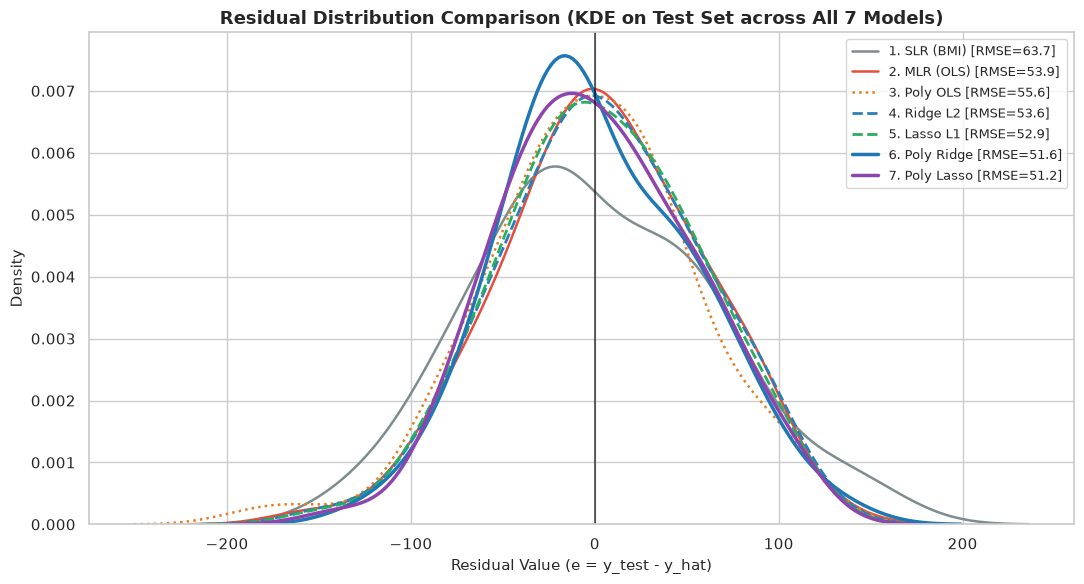

Comparison residuals plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_residuals.png


In [35]:
# 1. Overlaid Residual Distribution KDE Curves
plt.figure(figsize=(11, 6))

sns.kdeplot(residuals_test_simple, label=f"1. SLR (BMI) [RMSE={rmse_test_slr:.1f}]", color="#7f8c8d", linewidth=1.8)
sns.kdeplot(residuals_test_mlr, label=f"2. MLR (OLS) [RMSE={rmse_test_mlr:.1f}]", color="#e74c3c", linewidth=1.8)
sns.kdeplot(residuals_test_poly_ols, label=f"3. Poly OLS [RMSE={rmse_test_pols:.1f}]", color="#e67e22", linewidth=1.8, linestyle=":")
sns.kdeplot(residuals_test_ridge, label=f"4. Ridge L2 [RMSE={rmse_test_ridge:.1f}]", color="#2980b9", linewidth=2.0, linestyle="--")
sns.kdeplot(residuals_test_lasso, label=f"5. Lasso L1 [RMSE={rmse_test_lasso:.1f}]", color="#27ae60", linewidth=2.0, linestyle="--")
sns.kdeplot(residuals_test_poly_ridge, label=f"6. Poly Ridge [RMSE={rmse_test_pr:.1f}]", color="#1f77b4", linewidth=2.5)
sns.kdeplot(residuals_test_poly_lasso, label=f"7. Poly Lasso [RMSE={rmse_test_pl:.1f}]", color="#8e44ad", linewidth=2.5)

plt.axvline(0, color="black", linestyle="-", linewidth=1.2, alpha=0.7)
plt.title("Residual Distribution Comparison (KDE on Test Set across All 7 Models)", fontsize=13, fontweight="bold")
plt.xlabel("Residual Value (e = y_test - y_hat)", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.legend(frameon=True, fontsize=9.5)
plt.tight_layout()

comp_res_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_residuals.png")
plt.savefig(comp_res_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison residuals plot saved to: {comp_res_path}")


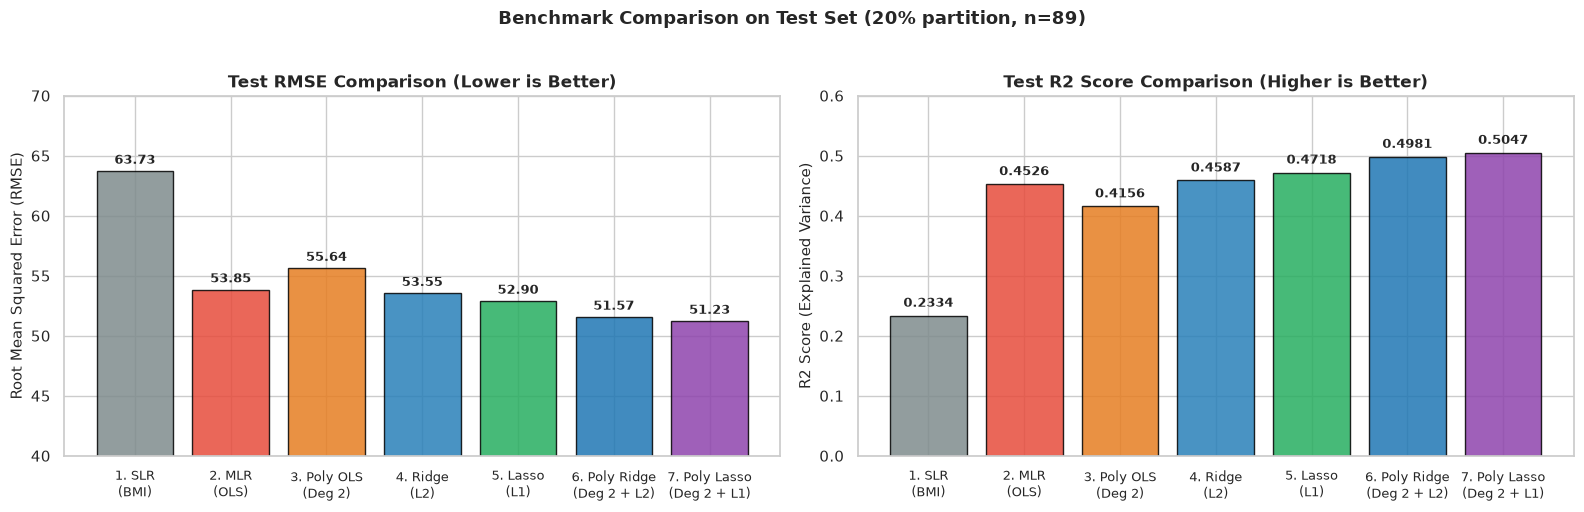

Comparison metrics bar chart saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_metrics_bars.png


In [36]:
# 2. Bar Chart Comparison of Test RMSE and Test R2 across All 7 Models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

model_short_labels = [
    "1. SLR\n(BMI)", "2. MLR\n(OLS)", "3. Poly OLS\n(Deg 2)", 
    "4. Ridge\n(L2)", "5. Lasso\n(L1)", "6. Poly Ridge\n(Deg 2 + L2)", "7. Poly Lasso\n(Deg 2 + L1)"
]
colors = ["#7f8c8d", "#e74c3c", "#e67e22", "#2980b9", "#27ae60", "#1f77b4", "#8e44ad"]

test_rmse_vals = model_comparison_df["Test RMSE"].values
test_r2_vals = model_comparison_df["Test R2"].values
x_pos = np.arange(len(model_short_labels))

# Test RMSE (Lower is better)
ax1.bar(x_pos, test_rmse_vals, color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Test RMSE Comparison (Lower is Better)", fontweight="bold", fontsize=12)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(model_short_labels, fontsize=9)
ax1.set_ylabel("Root Mean Squared Error (RMSE)")
ax1.set_ylim(40, 70)

for i, v in enumerate(test_rmse_vals):
    ax1.annotate(f"{v:.2f}", (x_pos[i], v + 0.6), ha="center", fontsize=9, fontweight="bold")

# Test R2 (Higher is better)
ax2.bar(x_pos, test_r2_vals, color=colors, edgecolor="black", alpha=0.85)
ax2.set_title("Test R2 Score Comparison (Higher is Better)", fontweight="bold", fontsize=12)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(model_short_labels, fontsize=9)
ax2.set_ylabel("R2 Score (Explained Variance)")
ax2.set_ylim(0, 0.60)

for i, v in enumerate(test_r2_vals):
    ax2.annotate(f"{v:.4f}", (x_pos[i], v + 0.015), ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Benchmark Comparison on Test Set (20% partition, n=89)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

comp_bars_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_metrics_bars.png")
plt.savefig(comp_bars_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison metrics bar chart saved to: {comp_bars_path}")


# ==========================================================================
# 13. Academic Discussion & University Key Takeaways
# ==========================================================================

### 1. Did using all features improve over BMI alone?
**Yes.** Simple linear regression on `bmi` achieved $R^2 = 0.2334$ (RMSE = $63.73$). Adding all 10 physiological features in Multiple Linear Regression jumped $R^2$ to $0.4526$ (RMSE = $53.85$), showing that blood lipids, blood pressure, and glucose provide vital clinical information.

---

### 2. What happened when we tested unregularized Polynomial Regression?
**It overfitted.**
- Training $R^2$ increased to $0.6062$ (Train RMSE fell to $48.92$).
- BUT Test RMSE worsened to **$55.64$** (Test $R^2$ fell to $0.4156$).
- **Explanation:** Generating 65 polynomial terms gave the model too much flexibility for only 353 training rows, leading to high variance and overfitting on unseen data.

---

### 3. How did Ridge ($L_2$) and Lasso ($L_1$) solve the polynomial overfitting?
**Regularization penalized complex weights and tamed the variance:**
- **Polynomial Ridge ($L_2$):** Shrunk all 65 weights toward zero, reducing Test RMSE from $55.64$ down to **$51.57$** ($R^2 = 0.4981$).
- **Polynomial Lasso ($L_1$):** Zeroed out 51 uninformative terms (78.5% sparsity), keeping only **14 active non-linear biomarkers**, achieving the best test performance: **Test RMSE = $51.23$** and **Test $R^2 = 0.5047$** (50.47%).

---

### 4. What non-linear interactions did Polynomial Lasso discover?
Lasso retained clinically meaningful terms:
- `bmi^2` ($+2.90$): Accelerating risk with higher obesity.
- `bmi * bp` ($+2.27$): Synergistic risk of metabolic syndrome (obesity combined with high blood pressure).
- `s6^2` ($+1.32$): Non-linear metabolic deterioration from elevated blood sugar.
- `age * bp` ($+0.71$) and `age * sex` ($+3.09$): Compounding demographic and vascular risk factors.

---

### 5. Why is `StandardScaler` inside the `Pipeline` strictly required?
1. **Fair Penalties:** Polynomial terms ($x_j^2, x_j x_k$) have different numerical ranges. Without scaling, regularizers would unfairly penalize terms with larger natural scales.
2. **No Data Leakage:** Standardizing inside `Pipeline` ensures scaling parameters $(\mu, \sigma)$ are learned strictly from the training data, with zero test data leakage.

---

### 6. Overall Best Model
**Polynomial Lasso ($L_1$, $\alpha=4.0$)** performed best overall:
- **Highest Test $R^2$:** **$0.5047$**
- **Lowest Test RMSE:** **$51.23$**
- **Interpretable:** Sparsity eliminated 51 redundant terms, leaving 14 key biomarkers.
